# Predicting PM2.5 from Multi-Sensor Air-Quality Readings
### End-to-end machine-learning project: problem framing → cleaning → EDA → feature engineering → reduction → scaling → modelling → diagnostics → recommendations

**Dataset:** `air_quality_dataset.csv` — 500 observations, 10 numeric columns: `PM2.5, PM10, NOx, NO2, SO2, VOCs, CO, CO2, CH4, Temperature`.

**Table of contents**
1. Problem statement
2. Proposed solution
3. Setup
4. Data audit and cleaning
5. Train/test split (done *before* any learning)
6. Exploratory data analysis and visualisation
7. Feature engineering (with the mathematics)
8. Feature reduction
9. Scaling / normalisation
10. Model zoo and cross-validated comparison
11. Hyper-parameter tuning with nested CV
12. Under-fitting / over-fitting diagnostics
13. Data-leakage audit
14. Final evaluation on the untouched test set
15. Recommendations and solution summary

---
## 1. Problem statement

**Business context.** Fine particulate matter (PM2.5, particles with aerodynamic diameter ≤ 2.5 µm) is the pollutant most strongly linked to cardiovascular and respiratory disease. Reference-grade PM2.5 monitors are expensive, need frequent calibration and are sparse. Cheaper gas sensors (NOx, NO₂, SO₂, VOCs, CO, CO₂, CH₄) and a temperature probe are widely deployed.

**Question.** *Can PM2.5 be estimated accurately from the other sensor channels* (a "virtual" or "soft" sensor), so that

* a PM2.5 monitor that fails or is missing can be back-filled, and
* locations with only gas sensors can still receive PM2.5 exposure estimates and health alerts?

**Formal task.** Supervised **regression**:

$$ \hat y = f_\theta(\mathbf{x}), \qquad y = \text{PM2.5}\ (\mu g/m^3),\quad \mathbf{x}\in\mathbb{R}^{9} $$

with $\mathbf{x}$ = {PM10, NOx, NO2, SO2, VOCs, CO, CO2, CH4, Temperature}.

**Success criteria** (decided *before* looking at model results):

| Criterion | Target |
|---|---|
| Generalisation error | Test RMSE clearly below the naive "predict the mean" baseline (RMSE ≈ σ_y) |
| Stability | CV standard deviation small relative to the mean; train–CV gap small |
| Honesty | No data leakage; fit/overfit diagnostics documented |
| Practical value | Correct health-category (AQI band) for most observations |

**Assumptions & caveats.** Rows are assumed i.i.d. (there is no timestamp or location column). Units are not given; relative magnitudes (e.g. CO2 ≈ 440, CH4 ≈ 2.1) suggest ppm for the gases and µg/m³ for particulates, but this is an *assumption*.

---
## 2. Proposed solution

A **leakage-safe scikit-learn pipeline**, so every learned quantity (imputation values, winsorisation bounds, scaler statistics, covariance matrices, selected features, model weights) is estimated **only on training folds**:

```
raw sensors ─► negative→NaN ─► median impute ─► winsorise (1–99 %) ─► feature engineering
            ─► scaling ─► (optional) feature selection / PCA ─► model ─► (target is standardised via TransformedTargetRegressor)
```

Plan:

1. Audit and clean the data with physical-validity rules (no negative concentrations, etc.).
2. **Split first** (80/20, stratified on target quintiles). The 20 % test set is touched **once**, at the end.
3. EDA on the training set only.
4. Engineer physically-motivated features (log transforms, chemistry ratios, Arrhenius temperature factor, Mahalanobis "unusualness" of the sensor vector).
5. Reduce features (VIF, clustering, LASSO, RFECV, PCA) and *test by cross-validation* whether reduction helps.
6. Compare scalers, then a zoo of models (linear, regularised, kernel, KNN, bagging, boosting) against a dummy baseline.
7. Tune the best families with **nested cross-validation** (unbiased estimate of the tuned model's performance), pick the final model with the **one-standard-error rule**.
8. Diagnose under-/over-fitting (learning curves, validation curves, bias–variance decomposition).
9. Audit leakage (permutation test, deliberately leaky feature, duplicates, autocorrelation, PM10 ablation).
10. Report test metrics with bootstrap confidence intervals, residual diagnostics, importances, and recommendations.

---
## 3. Setup

In [1]:
import warnings, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, uniform, randint
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from IPython.display import display, Markdown

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, RobustScaler, MinMaxScaler, PowerTransformer,
                                   QuantileTransformer, PolynomialFeatures, FunctionTransformer)
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold, cross_validate, cross_val_score,
                                     cross_val_predict, RandomizedSearchCV, learning_curve,
                                     validation_curve, permutation_test_score)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LassoCV, lasso_path
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor, IsolationForest)
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.feature_selection import SelectFromModel, RFECV, mutual_info_regression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, confusion_matrix, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson

warnings.filterwarnings("ignore")
RS = 42                                   # one global seed -> reproducible notebook
np.random.seed(RS)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.max_columns", 50)

TARGET = "PM2.5"
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

# Locate the data file (same folder as the notebook, or the upload location used when this was authored)

DATA_PATH = "air_quality_dataset.csv"

print("Using data file:", DATA_PATH)

Using data file: air_quality_dataset.csv


---
## 4. Data audit and cleaning

The cleaning steps that **do not learn anything from the data** (type checks, duplicates, physical-validity rules) are safe to run on the full dataset. Anything that *learns a statistic* (imputation values, outlier bounds, scalers) is deferred into the pipeline so it is fitted on training data only.

In [2]:
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)

display(df.head())

df.info()

Shape: (500, 10)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.9671,57.9260,116.1922,55.2303,4.5317,75.3173,2.7896,427.6743,1.7061,31.0851
1,101.9357,150.7743,76.8268,79.0516,18.7448,145.0840,1.9666,529.7396,2.4927,33.7111
2,70.9962,138.9488,158.7310,60.4666,14.8922,145.1473,2.6264,499.8894,2.4312,33.7787
3,28.4647,63.6439,25.3853,15.3333,7.6474,130.0223,1.7794,388.2837,1.8186,31.5659
4,78.2653,113.9779,105.6443,59.2023,17.6968,181.7137,3.2405,464.7392,2.5972,32.2298


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [3]:
# ---- 4.1 Structural audit -------------------------------------------------
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
    "min": df.min(), "max": df.max(),
    "negative_values": (df < 0).sum(),
})
display(audit)
print("Duplicate rows       :", df.duplicated().sum())
print("Non-finite (inf) vals:", int(np.isinf(df.select_dtypes("number")).sum().sum()))
print("Constant columns     :", [c for c in df if df[c].nunique() == 1])

,dtype,missing,n_unique,min,max,negative_values
PM2.5,float64,0,500,10.7576,127.6166,0
PM10,float64,0,500,12.9323,171.5942,0
NOx,float64,0,500,-0.0763,225.8869,1
NO2,float64,0,500,-1.9421,115.9164,1
SO2,float64,0,500,-1.0956,31.9419,2
VOCs,float64,0,500,27.5556,231.9260,0
CO,float64,0,500,0.3670,4.7989,0
CO2,float64,0,500,366.0632,558.9243,0
CH4,float64,0,500,1.3884,3.3523,0
Temperature,float64,0,500,19.5813,39.7787,0


Duplicate rows       : 0
Non-finite (inf) vals: 0
Constant columns     : []


In [4]:
# ---- 4.2 Physical-consistency rules ---------------------------------------
# Rule 1: concentrations cannot be negative.
# Rule 2: PM10 contains PM2.5 by definition, so PM10 >= PM2.5.
# Rule 3: NOx = NO + NO2, so NOx >= NO2.
neg_rows  = df[(df < 0).any(axis=1)]
pm_viol   = df[df["PM10"] < df["PM2.5"]]
nox_viol  = df[df["NO2"] > df["NOx"]]

print(f"Rule 1  negative readings           : {(df<0).sum().sum()} cells in {len(neg_rows)} rows")
print(f"Rule 2  PM10 < PM2.5 (impossible)    : {len(pm_viol)} rows ({len(pm_viol)/len(df):.1%})")
print(f"Rule 3  NO2 > NOx   (impossible)    : {len(nox_viol)} rows ({len(nox_viol)/len(df):.1%})")
display(neg_rows)

Rule 1  negative readings           : 4 cells in 4 rows
Rule 2  PM10 < PM2.5 (impossible)    : 36 rows (7.2%)
Rule 3  NO2 > NOx   (impossible)    : 21 rows (4.2%)


,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
121,35.4055,76.3279,39.5080,-1.9421,7.7839,98.2802,1.3352,393.0170,2.1315,28.4262
371,58.1676,41.8183,-0.0763,17.8559,8.4873,72.7448,1.1058,380.3026,2.0221,26.1211
425,50.7341,68.3721,97.3552,39.5943,-1.0956,71.5233,1.2867,421.3441,1.7480,28.2614
434,23.8333,69.7638,118.1156,31.1820,-0.3273,80.1824,1.7892,415.5374,1.9912,30.2773


**Cleaning decisions**

| Finding | Decision | Why |
|---|---|---|
| Negative concentrations (a handful of NOx / NO2 / SO2 cells) | Set to `NaN`, then **median-impute inside the pipeline** | Typical sensor-noise artefact near zero; physically impossible, so the value is untrustworthy, but the other columns in the row are fine. Deleting rows would waste data. |
| `PM10 < PM2.5` rows | **Keep, report only** | These are measurement inconsistencies, but the flag is computed *from the target*. Using it to drop rows or as a feature would be **target leakage** and would bias the test set. We later check model error on these rows separately. |
| `NO2 > NOx` rows | Keep; the engineered `NO_est = max(NOx − NO2, 0)` clips the impossible case | The flag uses only features, so it is leakage-safe. |
| No duplicates, no missing values, all float64 | Nothing to do | — |

In [5]:
# Stateless cleaning (no learned parameters => safe on the full data): negative -> NaN
df_clean = df.mask(df < 0)
print("NaNs introduced by rule 1:\n", df_clean.isna().sum()[lambda s: s > 0])
print("Rows dropped:", 0)

NaNs introduced by rule 1:
 NOx    1
NO2    1
SO2    2
dtype: int64
Rows dropped: 0


---
## 5. Train/test split — before any learning

The test set is locked away now. We stratify on target quintiles so train and test have the same PM2.5 distribution (important with only 500 rows).

In [6]:
y_bins = pd.qcut(df_clean[TARGET], q=5, labels=False)
train_df, test_df = train_test_split(df_clean, test_size=0.20, random_state=RS, stratify=y_bins)

X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_test,  y_test  = test_df.drop(columns=TARGET),  test_df[TARGET]
print(f"Train: {X_train.shape}   Test: {X_test.shape}")

# Is the stratified split representative? Two-sample Kolmogorov-Smirnov test on the target.
ks = stats.ks_2samp(y_train, y_test)
print(f"KS test train-vs-test target: D={ks.statistic:.3f}, p={ks.pvalue:.3f}  (p>0.05 => no evidence of distribution shift)")

# Baseline reference: the 'predict the training mean' RMSE equals the training std of the target.
BASELINE_RMSE = y_train.std()
print(f"Naive baseline RMSE (predict the mean) ~ {BASELINE_RMSE:.2f} ug/m3")

Train: (400, 9)   Test: (100, 9)
KS test train-vs-test target: D=0.052, p=0.976  (p>0.05 => no evidence of distribution shift)
Naive baseline RMSE (predict the mean) ~ 22.48 ug/m3


---
## 6. Exploratory data analysis (training set only)

All EDA below uses `train_df` so nothing learned about the test rows can influence modelling choices.

### 6.1 Target distribution

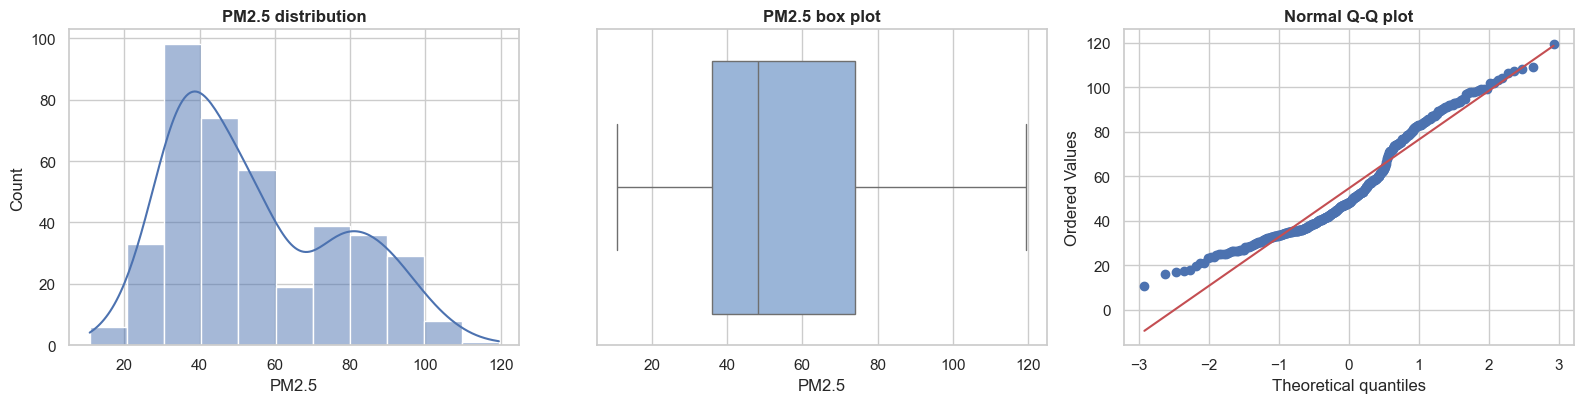

mean=54.61  median=48.31  std=22.48
skew=0.592  excess kurtosis=-0.689
Shapiro-Wilk p = 8.01e-12 | D'Agostino K2 p = 2.74e-09
Box-Cox lambda = 0.131  (lambda~1 => already near-symmetric; lambda~0 => log transform advisable)


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sns.histplot(y_train, kde=True, ax=axes[0], color="#4C72B0"); axes[0].set_title("PM2.5 distribution")
sns.boxplot(x=y_train, ax=axes[1], color="#8FB4E3");           axes[1].set_title("PM2.5 box plot")
stats.probplot(y_train, dist="norm", plot=axes[2]);            axes[2].set_title("Normal Q-Q plot")
plt.tight_layout(); plt.show()

print(f"mean={y_train.mean():.2f}  median={y_train.median():.2f}  std={y_train.std():.2f}")
print(f"skew={y_train.skew():.3f}  excess kurtosis={y_train.kurt():.3f}")
print("Shapiro-Wilk p =", f"{stats.shapiro(y_train)[1]:.2e}", "| D'Agostino K2 p =", f"{stats.normaltest(y_train)[1]:.2e}")
bc_y, lam = stats.boxcox(y_train)
print(f"Box-Cox lambda = {lam:.3f}  (lambda~1 => already near-symmetric; lambda~0 => log transform advisable)")

The target is **right-skewed (skew ≈ 0.6) and clearly multi-modal** — there is a main peak near 40 µg/m³ and a second shoulder/peak near 80 µg/m³ (the Q-Q plot has an S-shape). We investigate that in §6.6. Because regression metrics (RMSE) are scale-dependent and linear models assume roughly homoscedastic residuals, we will **standardise the target inside every pipeline** (`TransformedTargetRegressor`). That is mathematically harmless for tree models, essential for SVR, and keeps penalty strengths (`alpha`, `C`) on a comparable scale across models.

### 6.2 Feature distributions and normality

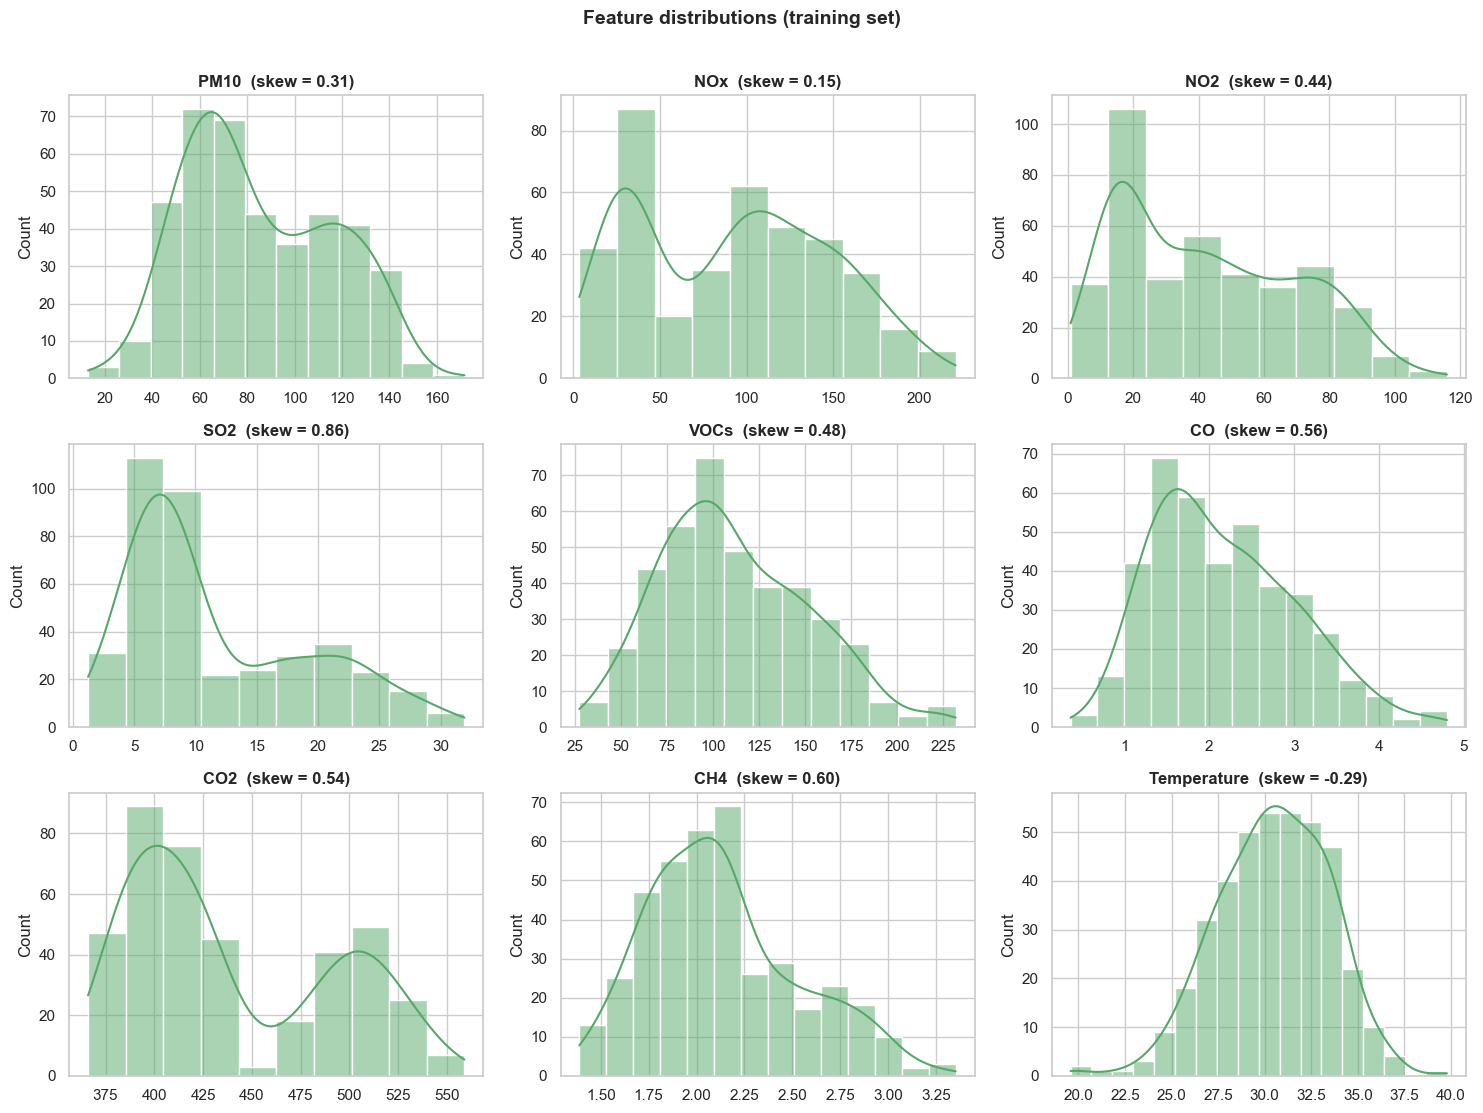

,skew,excess_kurtosis,Shapiro_p,DAgostino_p
feature,,,,
PM2.5,0.591688,-0.688560,8.01e-12,2.74e-09
PM10,0.314372,-0.868901,2.71e-08,2.23e-11
NOx,0.153802,-1.116563,8.81e-11,4.49e-32
NO2,0.444211,-0.973412,1.84e-12,2.17e-18
SO2,0.860588,-0.414907,2.39e-16,4.22e-10
VOCs,0.475130,-0.210864,1.27e-05,6.04e-04
CO,0.561497,-0.190862,2.84e-07,5.55e-05
CO2,0.540543,-1.161601,2.90e-16,5.76e-45
CH4,0.603869,-0.164671,3.21e-08,1.66e-05


In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), X_train.columns):
    sns.histplot(X_train[c], kde=True, ax=ax, color="#55A868")
    ax.set_title(f"{c}  (skew = {X_train[c].skew():.2f})")
    ax.set_xlabel("")
plt.suptitle("Feature distributions (training set)", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

rows = []
for c in train_df.columns:
    s = train_df[c].dropna()
    rows.append({"feature": c, "skew": s.skew(), "excess_kurtosis": s.kurt(),
                 "Shapiro_p": stats.shapiro(s)[1], "DAgostino_p": stats.normaltest(s)[1]})
norm_tbl = pd.DataFrame(rows).set_index("feature")
display(norm_tbl.style.format({"Shapiro_p": "{:.2e}", "DAgostino_p": "{:.2e}"}).background_gradient(subset=["skew"], cmap="coolwarm", vmin=-1, vmax=1))

**Reading the table.** Almost every pollutant rejects normality (p ≪ 0.05) with moderate positive skew (all below 0.9) and *negative* excess kurtosis (flat, light-tailed shapes — a hint of mixtures rather than heavy tails). `SO2` is the most skewed (≈ 0.86), followed by `CH4`, `CO`, `CO2`, `VOCs`, which motivates the log transforms in §7. `Temperature` is the only roughly Gaussian column.

### 6.3 Outlier analysis (univariate and multivariate consensus)

,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
IQR fences,0,0,0,0,1,3,0,3,4
|z|>3,0,0,0,0,0,1,0,1,3


Multivariate flags -> Mahalanobis(chi2 p<0.001): 2,  IsolationForest(2%): 8,  both: 1


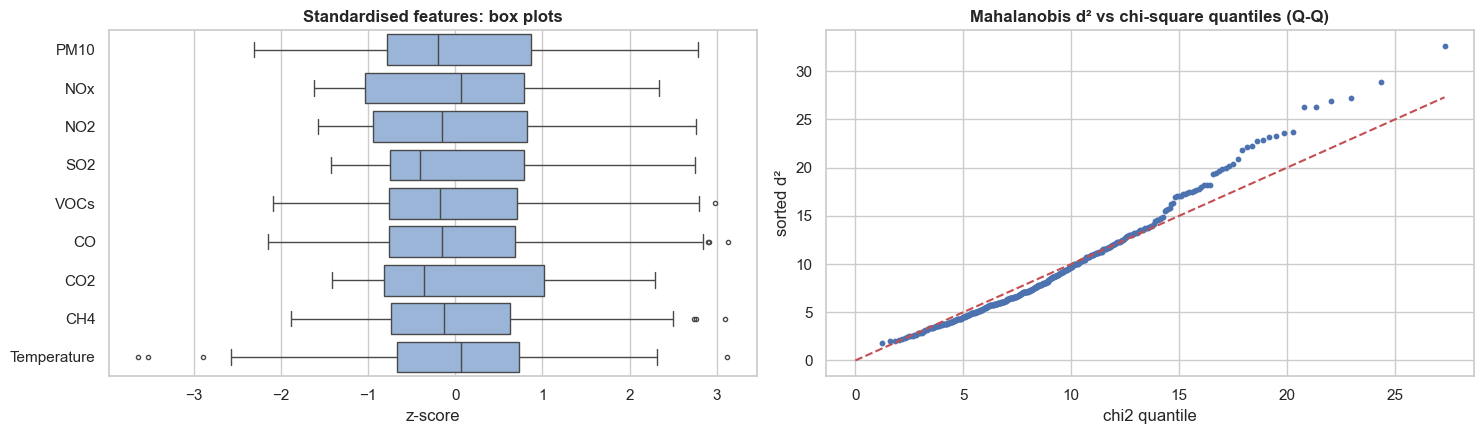

In [9]:
Xi = X_train.fillna(X_train.median())            # temporary fill, EDA only

# Univariate: Tukey fences and |z|>3
q1, q3 = Xi.quantile(.25), Xi.quantile(.75); iqr = q3 - q1
iqr_flags = (Xi < q1 - 1.5*iqr) | (Xi > q3 + 1.5*iqr)
z_flags   = ((Xi - Xi.mean())/Xi.std()).abs() > 3

# Multivariate: Mahalanobis distance^2 ~ chi2(p) under multivariate normality; Isolation Forest (distribution-free)
mu = Xi.mean().values; S_inv = np.linalg.inv(np.cov(Xi.values, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Xi.values - mu, S_inv, Xi.values - mu)
maha_flag = d2 > stats.chi2.ppf(0.999, df=Xi.shape[1])
iso_flag  = IsolationForest(n_estimators=300, contamination=0.02, random_state=RS).fit_predict(Xi) == -1

summary = pd.DataFrame({"IQR fences": iqr_flags.sum(), "|z|>3": z_flags.sum()})
display(summary.T)
print(f"Multivariate flags -> Mahalanobis(chi2 p<0.001): {maha_flag.sum()},  IsolationForest(2%): {iso_flag.sum()},  both: {(maha_flag & iso_flag).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=(Xi - Xi.mean())/Xi.std(), orient="h", ax=axes[0], color="#8FB4E3", fliersize=3)
axes[0].set_title("Standardised features: box plots"); axes[0].set_xlabel("z-score")
th = stats.chi2.ppf((np.arange(1, len(d2)+1) - .5)/len(d2), df=Xi.shape[1])
axes[1].scatter(th, np.sort(d2), s=10); axes[1].plot([0, th.max()], [0, th.max()], "r--")
axes[1].set_title("Mahalanobis d² vs chi-square quantiles (Q-Q)"); axes[1].set_xlabel("chi2 quantile"); axes[1].set_ylabel("sorted d²")
plt.tight_layout(); plt.show()

**Decision.** Outliers are very few (0–4 flagged per column by Tukey fences; only 2 of 400 rows exceed the 99.9 % chi-square cut-off, where ≈ 0.4 would be expected by chance). These look like genuine extreme-pollution events — **exactly the observations a PM2.5 estimator must handle** — so rows are **not removed**. Instead, a *train-fitted* **winsoriser** clips each feature to its 1st–99th percentile inside the pipeline, limiting the leverage of extreme values on linear/kernel models. §8 tests by CV whether this actually helps.

### 6.4 Relationships with the target

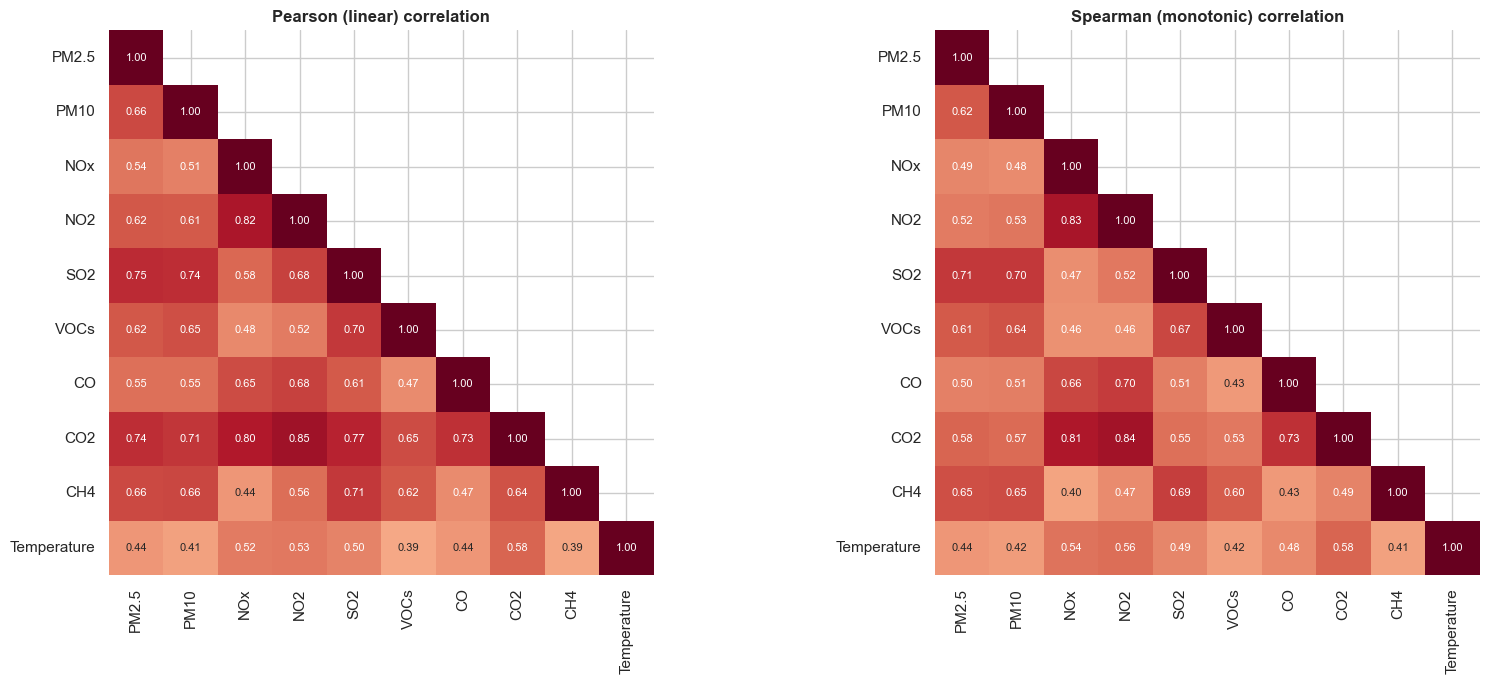

In [10]:
pear = train_df.corr(method="pearson")
spear = train_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, m, t in zip(axes, [pear, spear], ["Pearson (linear)", "Spearman (monotonic)"]):
    mask = np.triu(np.ones_like(m, dtype=bool), 1)
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, mask=mask,
                square=True, cbar=False, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{t} correlation")
plt.tight_layout(); plt.show()

,Pearson_r,p_value,Spearman_rho,mutual_info
feature,,,,
SO2,0.746691,4.1e-72,0.709277,0.487427
CO2,0.740220,1.3e-70,0.583297,0.437223
CH4,0.661752,9.8e-52,0.645881,0.301621
PM10,0.657415,7.4e-51,0.618269,0.336413
NO2,0.623643,2.2e-44,0.516906,0.325484
VOCs,0.621306,4.5e-44,0.613724,0.276137
CO,0.547593,1.1e-32,0.500213,0.253885
NOx,0.536958,3.5e-31,0.487115,0.312205
Temperature,0.437854,3.6e-20,0.442235,0.145257


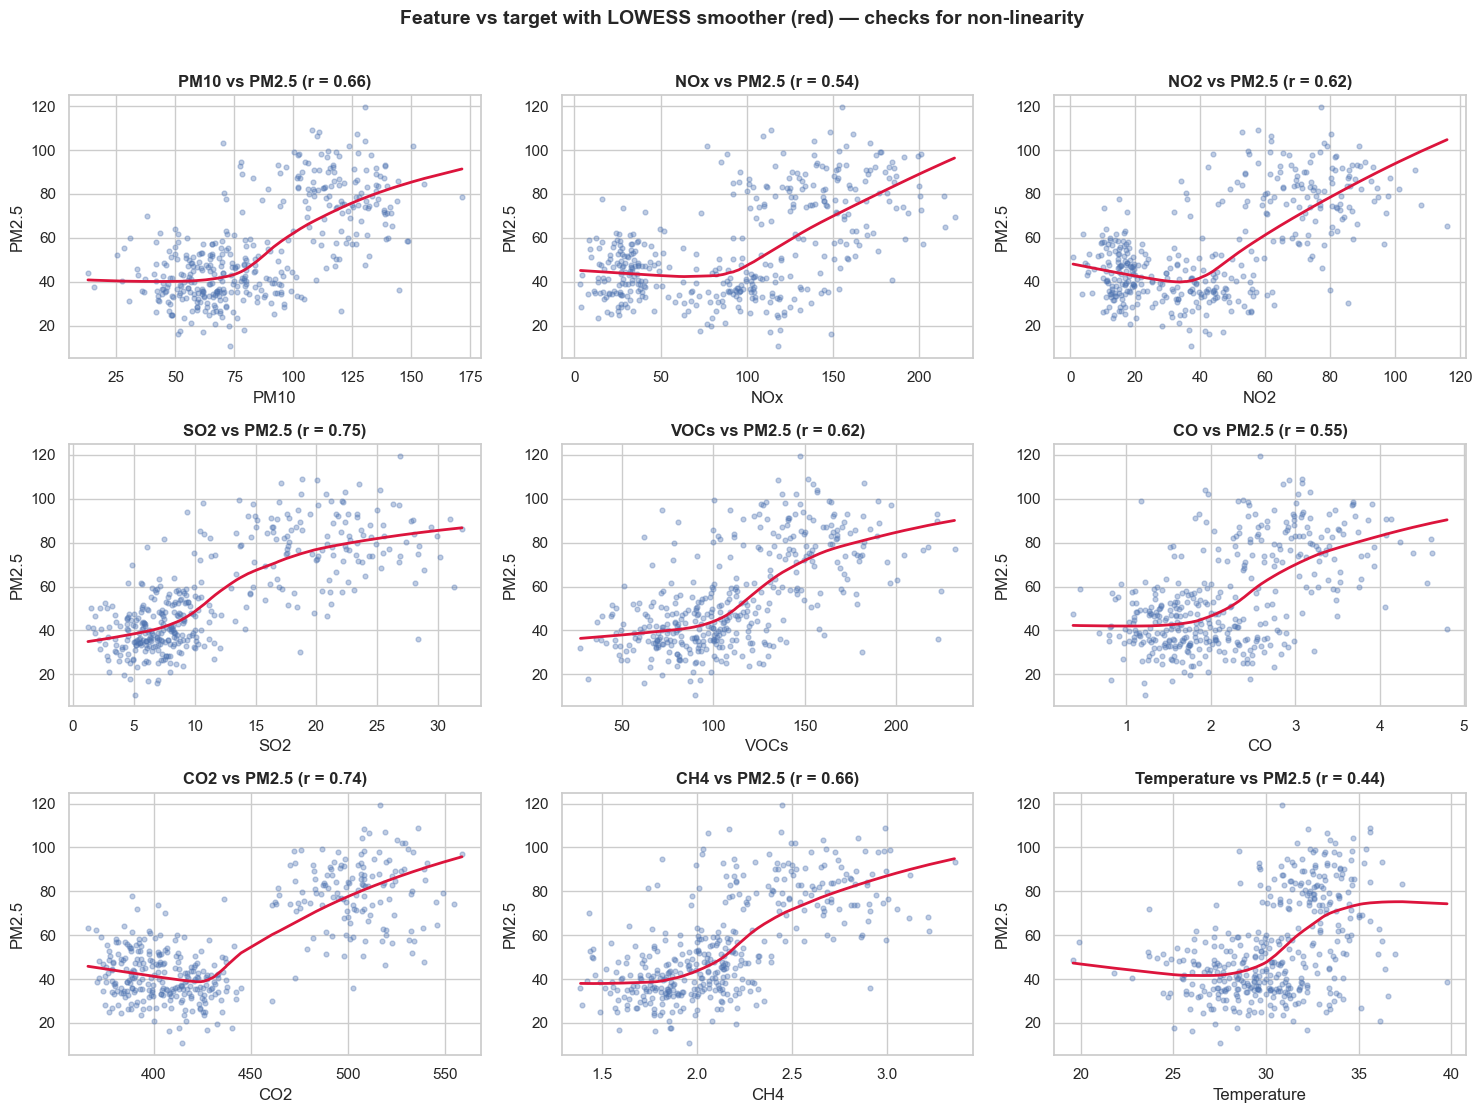

In [11]:
# Correlation with the target + p-values (pairwise-complete) + mutual information (captures non-linear dependence)
rows = []
mi = mutual_info_regression(Xi, y_train, random_state=RS)
for c, m_i in zip(X_train.columns, mi):
    ok = X_train[c].notna()
    r, p = stats.pearsonr(X_train.loc[ok, c], y_train[ok])
    rho, p_s = stats.spearmanr(X_train.loc[ok, c], y_train[ok])
    rows.append({"feature": c, "Pearson_r": r, "p_value": p, "Spearman_rho": rho, "mutual_info": m_i})
tgt_tbl = pd.DataFrame(rows).set_index("feature").sort_values("Pearson_r", ascending=False)
display(tgt_tbl.style.format({"p_value": "{:.1e}"}).background_gradient(cmap="Blues", subset=["Pearson_r", "Spearman_rho", "mutual_info"]))

fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), X_train.columns):
    sns.regplot(x=X_train[c], y=y_train, lowess=True, ax=ax,
                scatter_kws={"alpha": .35, "s": 12}, line_kws={"color": "crimson", "lw": 2})
    ax.set_title(f"{c} vs PM2.5 (r = {tgt_tbl.loc[c, 'Pearson_r']:.2f})"); ax.set_xlabel(c)
plt.suptitle("Feature vs target with LOWESS smoother (red) — checks for non-linearity", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

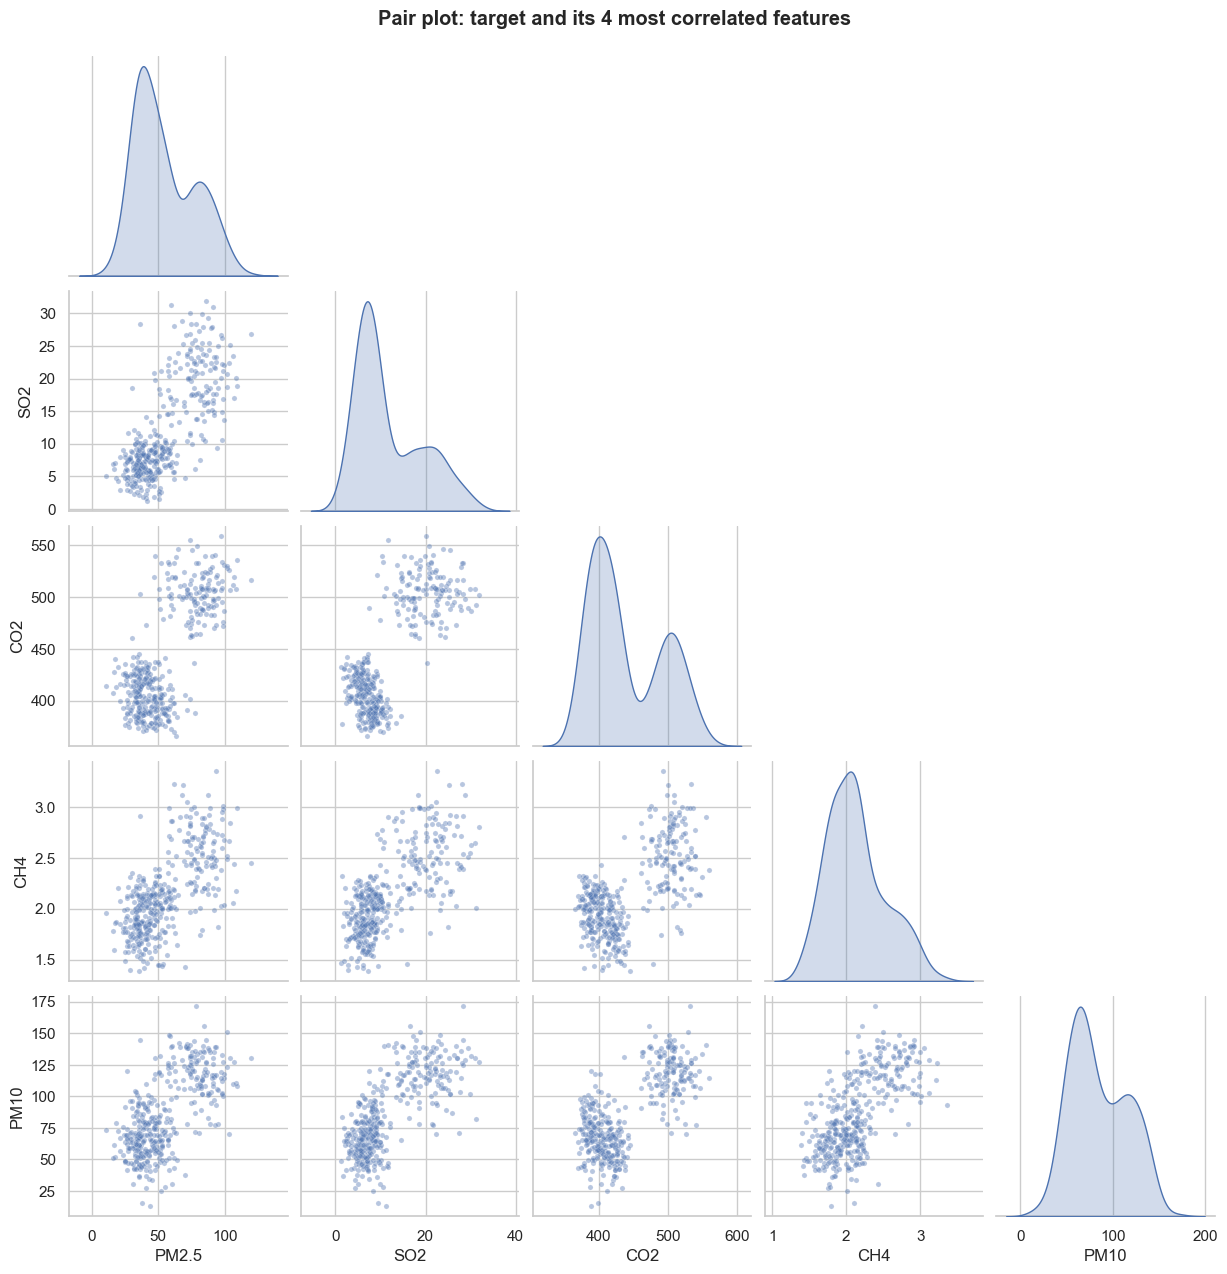

In [12]:
top4 = tgt_tbl.index[:4].tolist()
g = sns.pairplot(train_df[[TARGET] + top4], corner=True, diag_kind="kde", plot_kws={"alpha": .4, "s": 14})
g.fig.suptitle("Pair plot: target and its 4 most correlated features", y=1.02, fontweight="bold"); plt.show()

**Findings.**
* Every predictor is positively related to PM2.5; **SO2 (r≈0.75), CO2 (0.74), CH4 and PM10 (0.66)** are the strongest, then NO2 and VOCs (0.62). All p-values are essentially 0.
* The LOWESS smoothers are **S-shaped, not straight**: flat at low sensor values, a steep rise in the middle (e.g. CO2 ≈ 430–470, SO2 ≈ 10–15), and a plateau at high values. That is the signature of a *step between two regimes* rather than a smooth linear dose–response — and it explains why the Spearman correlations are lower than Pearson for CO2 and NO2. We examine this in §6.6.
* Predictors are strongly inter-correlated (e.g. NO2–NOx ≈ 0.8, CO2–NO2 ≈ 0.84): the sensors share common emission sources (combustion/traffic/industry). That calls for **multicollinearity diagnostics** and regularisation.

### 6.5 Multicollinearity (VIF) and latent structure (PCA)

In [13]:
# Variance Inflation Factor: VIF_j = 1 / (1 - R_j^2), where R_j^2 is from regressing feature j on all other features.
Xs = pd.DataFrame(StandardScaler().fit_transform(Xi), columns=Xi.columns)
Xc = sm.add_constant(Xs)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=Xs.columns, name="VIF").sort_values(ascending=False)
display(vif.to_frame().style.background_gradient(cmap="OrRd"))
print("Rule of thumb: VIF>5 moderate, VIF>10 severe collinearity.")

,VIF
CO2,6.808662
NO2,4.626789
NOx,3.738883
SO2,3.708985
PM10,2.743891
CH4,2.316896
VOCs,2.300138
CO,2.277573
Temperature,1.548837


Rule of thumb: VIF>5 moderate, VIF>10 severe collinearity.


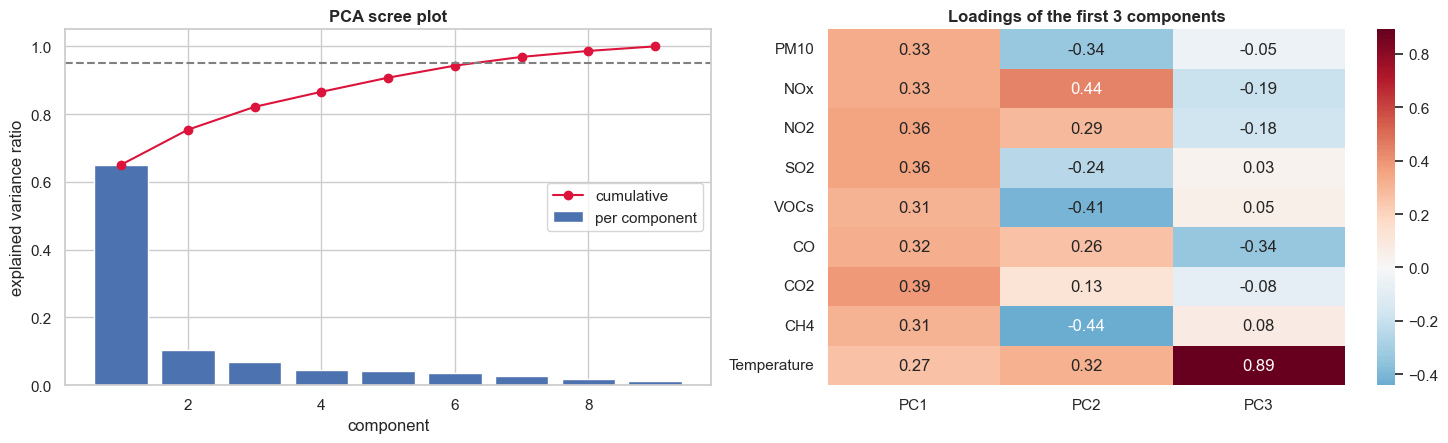

PC1 explains 65.1% of the variance.  Components needed for 90% / 95% variance: 5 / 7


In [14]:
# PCA on standardised predictors (exploratory; the eigen-decomposition of the correlation matrix R = V L V^T)
pca_eda = PCA().fit(Xs)
evr = pca_eda.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].bar(range(1, len(evr)+1), evr, color="#4C72B0", label="per component")
axes[0].plot(range(1, len(evr)+1), np.cumsum(evr), "o-", color="crimson", label="cumulative")
axes[0].axhline(.95, ls="--", c="grey"); axes[0].set_xlabel("component"); axes[0].set_ylabel("explained variance ratio")
axes[0].set_title("PCA scree plot"); axes[0].legend()
load = pd.DataFrame(pca_eda.components_[:3].T, index=Xs.columns, columns=["PC1", "PC2", "PC3"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1]); axes[1].set_title("Loadings of the first 3 components")
plt.tight_layout(); plt.show()
print(f"PC1 explains {evr[0]:.1%} of the variance.  Components needed for 90% / 95% variance:", int(np.searchsorted(np.cumsum(evr), .90)+1), "/", int(np.searchsorted(np.cumsum(evr), .95)+1))

**Interpretation.** PC1 loads positively on *every* pollutant — a general "pollution load" axis explaining a large chunk of the variance — while PC2/PC3 separate temperature and particle/combustion contrasts. The first component alone carries about two thirds of the variance, so the nine sensors move together; PC3 is almost pure Temperature (loading 0.89). Raw-feature VIFs are moderate (max ≈ 6.8 for CO2, none above 10); they become extreme once engineered features are added (§8), which is why regularisation and selection matter.

### 6.6 Latent structure: are there hidden pollution regimes?

  File "C:\Users\SKYTECH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\SKYTECH\anaconda3\Lib\sub

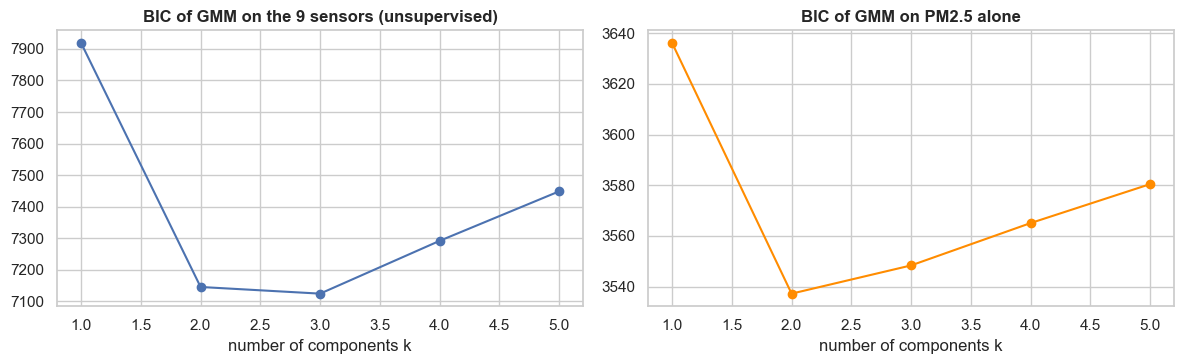

Best k by BIC  -> sensors: 3 | PM2.5: 2


In [15]:
# Hint from 6.1 and 6.4: bimodal target + S-shaped relationships.  Fit Gaussian mixtures (EM algorithm) and compare by BIC.
#   BIC = k_params * ln(n) - 2 * ln(L)   (lower = better trade-off between fit and complexity)
Zr = Xi.copy()
for c in Zr.columns:
    if c != "Temperature": Zr[c] = np.log1p(Zr[c].clip(lower=0))
Zs = StandardScaler().fit_transform(Zr)
ks_ = range(1, 6)
bic_x = [GaussianMixture(k, n_init=5, random_state=RS).fit(Zs).bic(Zs) for k in ks_]
bic_y = [GaussianMixture(k, n_init=5, random_state=RS).fit(y_train.values.reshape(-1, 1)).bic(y_train.values.reshape(-1, 1)) for k in ks_]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(ks_, bic_x, "o-"); axes[0].set_title("BIC of GMM on the 9 sensors (unsupervised)"); axes[0].set_xlabel("number of components k")
axes[1].plot(ks_, bic_y, "o-", color="darkorange"); axes[1].set_title("BIC of GMM on PM2.5 alone"); axes[1].set_xlabel("number of components k")
plt.tight_layout(); plt.show()
print("Best k by BIC  -> sensors:", list(ks_)[int(np.argmin(bic_x))], "| PM2.5:", list(ks_)[int(np.argmin(bic_y))])

,n,PM25_mean,PM25_std,PM10_mean,SO2_mean,CO2_mean,NO2_mean,Temperature_mean
regime,,,,,,,,
regime 0 (cleaner air),257,40.8666,10.9947,65.9894,6.9531,403.9965,26.2069,29.1923
regime 1 (polluted episode),143,79.3058,15.6696,118.9205,20.3222,504.2706,72.1181,32.7476


Welch t-test on PM2.5 between regimes: t = -26.0, p = 3.6e-69;  Cohen's d = 2.99
Share of PM2.5 variance explained by regime membership alone (eta^2): 67.3%
In-sample RMSE of the 'predict the regime mean' rule: 12.83   (naive baseline 22.48)
  within regime 0 (cleaner air)      : n=257, ridge CV R2 = +0.062
  within regime 1 (polluted episode) : n=143, ridge CV R2 = -0.212


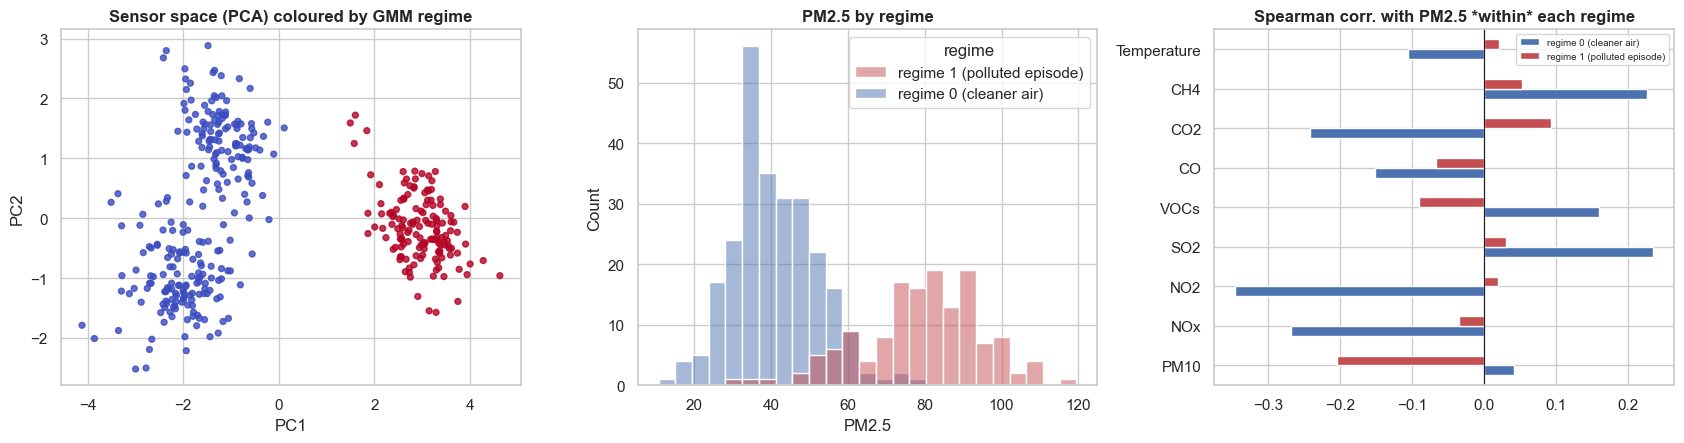

In [16]:
# Two-regime solution: profile each regime (training data only)
gm2 = GaussianMixture(2, n_init=10, random_state=RS).fit(Zs)
order = np.argsort(gm2.means_.sum(axis=1)); regime = pd.Series(np.argsort(order)[gm2.predict(Zs)], index=Xi.index, name="regime")
names = {0: "regime 0 (cleaner air)", 1: "regime 1 (polluted episode)"}
prof = train_df.assign(regime=regime.map(names)).groupby("regime").agg(n=("PM2.5", "size"), PM25_mean=("PM2.5", "mean"), PM25_std=("PM2.5", "std"),
        **{f"{c}_mean": (c, "mean") for c in ["PM10", "SO2", "CO2", "NO2", "Temperature"]})
display(prof)

a, b = y_train[regime == 0], y_train[regime == 1]
welch = stats.ttest_ind(a, b, equal_var=False); pooled = np.sqrt((a.var()*(len(a)-1) + b.var()*(len(b)-1)) / (len(a)+len(b)-2))
print(f"Welch t-test on PM2.5 between regimes: t = {welch.statistic:.1f}, p = {welch.pvalue:.1e};  Cohen's d = {(b.mean()-a.mean())/pooled:.2f}")
eta2 = 1 - ((y_train - y_train.groupby(regime).transform('mean'))**2).sum() / ((y_train - y_train.mean())**2).sum()
print(f"Share of PM2.5 variance explained by regime membership alone (eta^2): {eta2:.1%}")
print(f"In-sample RMSE of the 'predict the regime mean' rule: {np.sqrt(((y_train - y_train.groupby(regime).transform('mean'))**2).mean()):.2f}   (naive baseline {BASELINE_RMSE:.2f})")

# Within a regime, do the sensors still predict PM2.5?  (5-fold CV R2 of a ridge regression fitted inside each regime)
for r_ in [0, 1]:
    m = (regime == r_).values
    r2w = cross_val_score(RidgeCV(alphas=np.logspace(-2, 3, 20)), Xi[m], y_train[m], cv=5, scoring="r2")
    print(f"  within {names[r_]:28s}: n={m.sum():3d}, ridge CV R2 = {r2w.mean():+.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
p2 = PCA(2).fit_transform(Zs)
sc_ = axes[0].scatter(p2[:, 0], p2[:, 1], c=regime, cmap="coolwarm", s=18, alpha=.8); axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("Sensor space (PCA) coloured by GMM regime")
sns.histplot(x=y_train, hue=regime.map(names), bins=25, multiple="layer", ax=axes[1], palette={names[0]: "#4C72B0", names[1]: "#C44E52"}); axes[1].set_title("PM2.5 by regime"); axes[1].set_xlabel("PM2.5")
wc = pd.DataFrame({names[r_]: Xi[(regime == r_).values].corrwith(y_train[(regime == r_).values], method="spearman") for r_ in [0, 1]})
wc.plot.barh(ax=axes[2], color=["#4C72B0", "#C44E52"]); axes[2].axvline(0, c="k", lw=.8); axes[2].set_title("Spearman corr. with PM2.5 *within* each regime"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Key discovery.** The sensor data fall into **two well-separated pollution regimes**: a large "cleaner air" group (≈ 64 % of rows, PM2.5 ≈ 41 µg/m³) and a smaller "polluted episode" group (≈ 36 %, PM2.5 ≈ 79 µg/m³; Cohen's d ≈ 3.0). Knowing the regime alone explains roughly two thirds of the variance of PM2.5, and — crucially — **inside a regime the sensors have almost no remaining linear predictive power** (within-regime ridge CV R² ≈ 0 or negative; within-regime correlations are weak).

Consequences for the project:
1. The task is mostly **"which regime am I in?" plus a regime-specific level**, not a smooth dose-response. That explains the S-shaped scatter plots and the tree models' step-like predictions.
2. The remaining within-regime scatter (σ ≈ 11–16 µg/m³) acts like **irreducible noise** for these sensors — so the achievable R² has a ceiling of about 0.65–0.70, and "better" algorithms will not break through it.
3. A natural, interpretable feature is the **posterior regime probability** $P(\text{regime}\mid\mathbf x)$ from a Gaussian mixture fitted on the sensors only (§7). It uses no target information, so it is leakage-free if fitted on training folds, and it turns a non-linear problem into one a linear model can solve (a *mixture-of-experts* view: $\hat y = \sum_j P(j\mid \mathbf x)\,\mu_j$).

*Number of regimes:* BIC on the PM2.5 values alone is minimised at **k = 2**, whereas BIC on the nine sensors prefers **k = 3** (a third, intermediate group). Both options are tested by cross-validation in §8.1.

---
## 7. Feature engineering (with the mathematics)

All transformers are written as scikit-learn estimators so their learned state comes **only from the training fold**.

### Pre-processing transformers
* **`NegativeToNaN`** – stateless validity rule.
* **Median imputation** – $x_{ij} \leftarrow \operatorname{median}(x_{\cdot j}^{train})$.
* **`Winsorizer`** – $x \leftarrow \min\!\big(\max(x,\,q_{0.01}),\,q_{0.99}\big)$ with quantiles taken from the training fold.

### Engineered features (none uses the target!)

| Feature | Formula | Rationale |
|---|---|---|
| Log transforms | $\tilde x = \ln(1+x)$ for SO2, CO, CH4, VOCs, NO2, NOx | Variance stabilisation; a log-normal variable becomes Gaussian, and multiplicative effects become additive. |
| Estimated NO | $\text{NO}_{est}=\max(\text{NOx}-\text{NO2},0)$ | $\text{NOx}=\text{NO}+\text{NO}_2$ by definition. |
| NO₂ fraction | $\text{NO2}/(\text{NOx}+1)$ | Degree of NO→NO₂ oxidation (photochemical ageing of the air mass). |
| CO / CO₂ ratio | $\text{CO}/\text{CO}_2$ | Combustion-efficiency proxy: incomplete combustion produces relatively more CO. |
| CH₄ / CO₂ ratio | $\text{CH}_4/\text{CO}_2$ | Separates fugitive/biogenic sources from combustion. |
| VOC / NOx ratio | $\text{VOCs}/(\text{NOx}+1)$ | Photochemical regime indicator; controls secondary organic aerosol formation. |
| SO₂–NO₂ geometric mean | $\sqrt{\text{SO}_2\cdot\text{NO}_2}$ | Secondary inorganic aerosol (sulphate, nitrate) needs *both* precursors; unlike an arithmetic mean, the geometric mean is large only when both are high. |
| Temperature curvature | $(T-\bar T_{train})^2$ | Captures non-monotonic temperature effects. |
| Arrhenius factor | $A(T)=\exp\!\Big[-\tfrac{E_a}{R}\Big(\tfrac1{T_K}-\tfrac1{T_{0}}\Big)\Big]$, $T_K=T+273.15$, $E_a/R\approx5000$ K | Reaction rates (hence secondary aerosol formation) grow exponentially with temperature. $E_a/R$ is an illustrative constant. |
| Temp × VOC | $(T-\bar T)\cdot\ln(1+\text{VOCs})$ | Temperature-dependent VOC reactivity. |
| **Mahalanobis distance** | $d_M(\mathbf x)=\sqrt{(\mathbf z-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf z-\boldsymbol\mu)}$, with $\mathbf z=\ln(1+\mathbf x_{conc})$ and $\boldsymbol\mu,\Sigma$ from the training fold | How unusual is the whole sensor vector, accounting for correlations. Heavily polluted episodes sit far from the centroid. |
| **GMM regime probabilities** (`RegimeFeatures`, §6.6) | $P(j\mid\mathbf x)=\dfrac{\pi_j\,\mathcal N(\mathbf z;\boldsymbol\mu_j,\Sigma_j)}{\sum_l \pi_l\,\mathcal N(\mathbf z;\boldsymbol\mu_l,\Sigma_l)}$, parameters learned by EM on the training fold's sensors only | Soft membership of the "cleaner" vs "polluted" regime; the first regime is dropped as the reference level because the probabilities sum to 1. **Unsupervised → no target leakage.** |

The regime features are optional (a model-pipeline switch) and are evaluated against the alternatives by CV in §8.1.

**Why not `PM2.5 / PM10`?** Because that ratio contains the target — we demonstrate in §13 what happens if you use it.

In [17]:
class NegativeToNaN(BaseEstimator, TransformerMixin):
    # Physical-validity rule: concentrations/temperature readings below zero are sensor artefacts -> NaN.
    def fit(self, X, y=None): return self
    def transform(self, X):
        X = pd.DataFrame(X).copy()
        return X.mask(X < 0)


class Winsorizer(BaseEstimator, TransformerMixin):
    # Clip every column to [q_lower, q_upper]; the quantiles are learned on the training fold only.
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.lo_, self.hi_ = X.quantile(self.lower), X.quantile(self.upper)
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(lower=self.lo_, upper=self.hi_, axis=1)


class FeatureEngineer(BaseEstimator, TransformerMixin):
    # Physically-motivated features. Learns only (mean T, mean/cov of log-concentrations) from training data.
    def __init__(self, ea_over_r=5000.0, t_ref_c=25.0):
        self.ea_over_r, self.t_ref_c = ea_over_r, t_ref_c

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.conc_cols_ = [c for c in X.columns if c != "Temperature"]
        L = np.log1p(X[self.conc_cols_].clip(lower=0)).to_numpy()
        self.mu_ = L.mean(axis=0)                                  # centroid of log-concentrations
        self.cov_inv_ = np.linalg.pinv(np.cov(L, rowvar=False))    # Sigma^{-1} (pseudo-inverse for numerical safety)
        self.t_mean_ = X["Temperature"].mean() if "Temperature" in X else 0.0
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        out, g, eps = X.copy(), X[self.conc_cols_].clip(lower=0), 1e-6
        has = lambda *cols: all(c in g.columns for c in cols)

        for c in ["SO2", "CO", "CH4", "VOCs", "NO2", "NOx"]:                    # 1) variance-stabilising logs
            if c in g: out[f"log_{c}"] = np.log1p(g[c])
        if has("NOx", "NO2"):                                                    # 2) NOx chemistry
            out["NO_est"]     = (g["NOx"] - g["NO2"]).clip(lower=0)
            out["NO2_to_NOx"] = g["NO2"] / (g["NOx"] + 1.0)
        if has("CO", "CO2"):  out["CO_to_CO2"]  = g["CO"]  / (g["CO2"] + eps)   # 3) source-signature ratios
        if has("CH4", "CO2"): out["CH4_to_CO2"] = g["CH4"] / (g["CO2"] + eps)
        if has("VOCs", "NOx"): out["VOC_to_NOx"] = g["VOCs"] / (g["NOx"] + 1.0)
        if has("SO2", "NO2"): out["geo_SO2_NO2"] = np.sqrt(g["SO2"] * g["NO2"])             # 4) secondary-aerosol precursors
        if "Temperature" in X:                                                   # 5) temperature physics
            T = X["Temperature"]; Tk = T + 273.15; T0 = self.t_ref_c + 273.15
            out["Temp_sq"]    = (T - self.t_mean_) ** 2
            out["Arrhenius"]  = np.exp(-self.ea_over_r * (1.0 / Tk - 1.0 / T0))
            if "VOCs" in g: out["Temp_x_logVOC"] = (T - self.t_mean_) * np.log1p(g["VOCs"])
        D = np.log1p(g).to_numpy() - self.mu_                                    # 6) Mahalanobis distance
        out["mahalanobis"] = np.sqrt(np.maximum(np.einsum("ij,jk,ik->i", D, self.cov_inv_, D), 0))
        return out


RAW_COLS = ["PM10", "NOx", "NO2", "SO2", "VOCs", "CO", "CO2", "CH4", "Temperature"]

class RegimeFeatures(BaseEstimator, TransformerMixin):
    # Unsupervised latent-regime features: a Gaussian mixture is fitted on the (log-)sensor vector of the TRAINING fold only,
    # and the posterior membership probabilities P(regime j | x) are appended. The target is never used => no target leakage.
    def __init__(self, n_regimes=2, random_state=42):
        self.n_regimes, self.random_state = n_regimes, random_state
    def _prep(self, X):
        Z = X[self.cols_].copy()
        for c in self.cols_:
            if c != "Temperature": Z[c] = np.log1p(Z[c].clip(lower=0))
        return Z
    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.cols_ = [c for c in RAW_COLS if c in X.columns]
        Z = self._prep(X); self.sc_ = StandardScaler().fit(Z)
        self.gmm_ = GaussianMixture(self.n_regimes, covariance_type="full", n_init=5, random_state=self.random_state).fit(self.sc_.transform(Z))
        self.order_ = np.argsort(self.gmm_.means_.sum(axis=1))      # deterministic labelling: regime 0 = cleanest air
        return self
    def transform(self, X):
        X = pd.DataFrame(X)
        P = self.gmm_.predict_proba(self.sc_.transform(self._prep(X)))[:, self.order_]
        out = X.copy()
        for j in range(1, self.n_regimes):                           # drop regime 0: probabilities sum to 1 (dummy-variable trap)
            out[f"regime_p{j}"] = P[:, j]
        return out


class CorrelationFilter(BaseEstimator, TransformerMixin):
    # Unsupervised: drop one of any pair with |corr| > threshold (never looks at y => cannot leak the target).
    def __init__(self, threshold=0.95):
        self.threshold = threshold
    def fit(self, X, y=None):
        X = pd.DataFrame(X); c = X.corr().abs()
        upper = c.where(np.triu(np.ones(c.shape), 1).astype(bool))
        self.drop_ = [col for col in upper.columns if (upper[col] > self.threshold).any()]
        self.keep_ = [col for col in X.columns if col not in self.drop_]
        return self
    def transform(self, X):
        return pd.DataFrame(X)[self.keep_]

# Sanity guard: the target must never be an input of any transformer
assert TARGET not in X_train.columns and TARGET not in X_test.columns

Raw features: 9  ->  engineered feature matrix: 25 columns
New features: ['log_SO2', 'log_CO', 'log_CH4', 'log_VOCs', 'log_NO2', 'log_NOx', 'NO_est', 'NO2_to_NOx', 'CO_to_CO2', 'CH4_to_CO2', 'VOC_to_NOx', 'geo_SO2_NO2', 'Temp_sq', 'Arrhenius', 'Temp_x_logVOC', 'mahalanobis']


,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
Yeo-Johnson lambda,0.3682,0.5704,0.3169,-0.0435,0.3760,-0.1063,-2.9012,-1.1221,1.7594


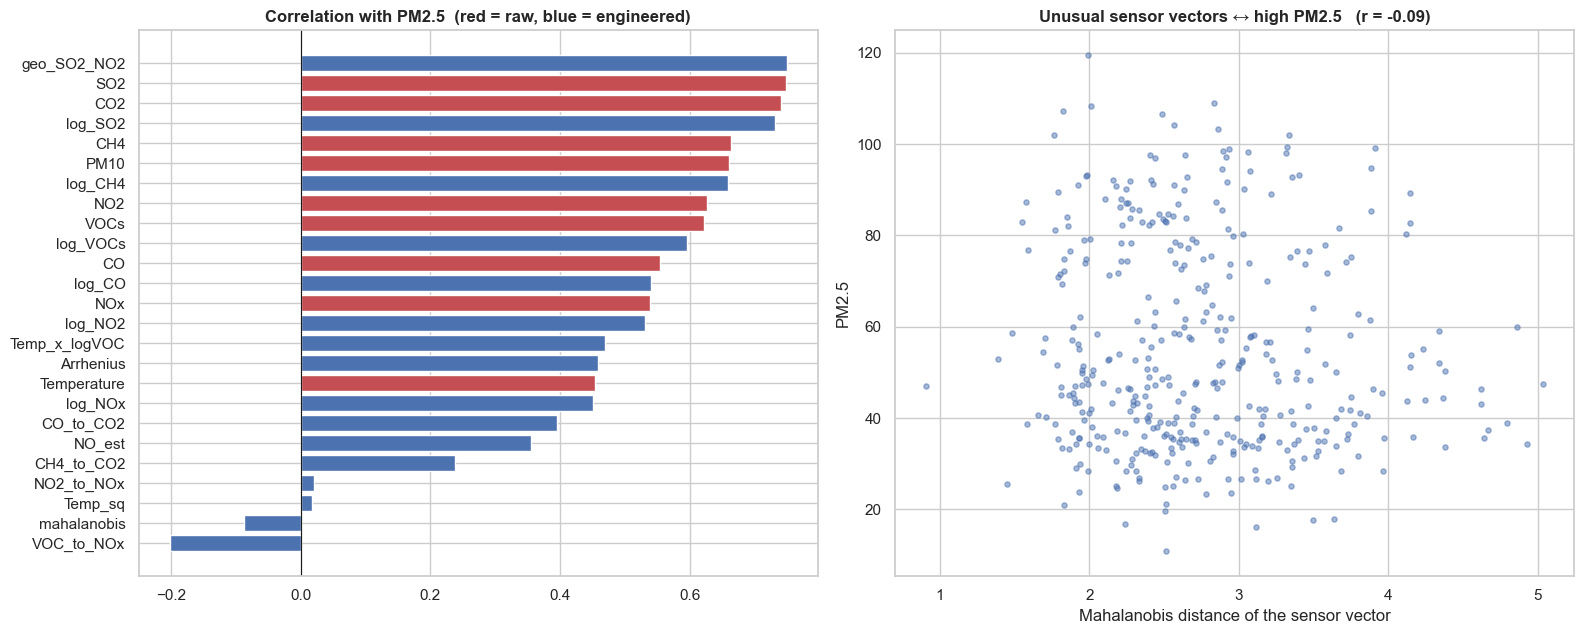

In [18]:
# Demonstration on the training set (the same steps run inside the pipeline later)
prep = Pipeline([("clean", NegativeToNaN()),
                 ("impute", SimpleImputer(strategy="median").set_output(transform="pandas")),
                 ("winsor", Winsorizer(0.01, 0.99))])
Xp = prep.fit_transform(X_train)
fe_demo = FeatureEngineer().fit(Xp)
Xe = fe_demo.transform(Xp)
print(f"Raw features: {Xp.shape[1]}  ->  engineered feature matrix: {Xe.shape[1]} columns")
print("New features:", [c for c in Xe.columns if c not in Xp.columns])

# Yeo-Johnson lambdas: lambda<1 => a right-skewed feature wants compression
yj = PowerTransformer(method="yeo-johnson").fit(Xp)
display(pd.Series(yj.lambdas_, index=Xp.columns, name="Yeo-Johnson lambda").to_frame().T)

corr_y = Xe.corrwith(y_train).sort_values()
colors = ["#C44E52" if c in Xp.columns else "#4C72B0" for c in corr_y.index]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].barh(corr_y.index, corr_y.values, color=colors); axes[0].set_title("Correlation with PM2.5  (red = raw, blue = engineered)")
axes[0].axvline(0, c="k", lw=.8)
axes[1].scatter(Xe["mahalanobis"], y_train, s=14, alpha=.5)
axes[1].set_xlabel("Mahalanobis distance of the sensor vector"); axes[1].set_ylabel("PM2.5")
axes[1].set_title(f"Unusual sensor vectors ↔ high PM2.5   (r = {np.corrcoef(Xe['mahalanobis'], y_train)[0,1]:.2f})")
plt.tight_layout(); plt.show()

---
## 8. Feature reduction

Adding 14 engineered columns to 9 raw ones creates redundancy. We (a) diagnose it, (b) apply several reduction techniques, and (c) **let cross-validation decide** whether reduction or engineering helps at all — more features are not automatically better with only 400 training rows.

VIF after feature engineering (top 12) – severe collinearity expected:


,VIF
Temperature,70965.487162
Arrhenius,69878.931834
NOx,2819.116461
NO_est,1175.171688
NO2,683.859314
log_CH4,578.511854
Temp_sq,481.383151
CO_to_CO2,421.275050
CO2,309.711133
Temp_x_logVOC,256.889999


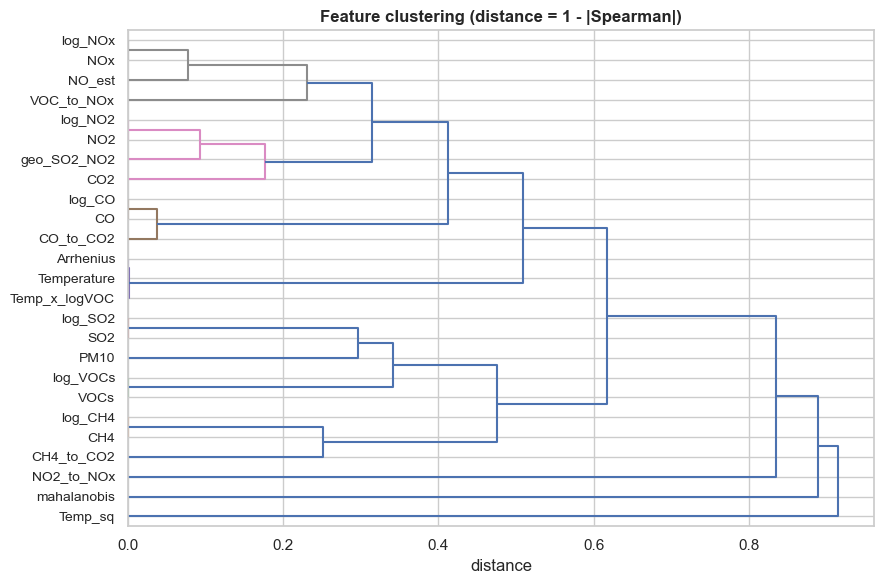

In [19]:
Xe_s = pd.DataFrame(StandardScaler().fit_transform(Xe), columns=Xe.columns)
vif_e = pd.Series([variance_inflation_factor(sm.add_constant(Xe_s).values, i) for i in range(1, Xe_s.shape[1]+1)], index=Xe_s.columns).sort_values(ascending=False)
print("VIF after feature engineering (top 12) – severe collinearity expected:")
display(vif_e.head(12).to_frame("VIF").style.background_gradient(cmap="OrRd"))

# Hierarchical clustering on distance = 1 - |Spearman rho| shows the redundant groups
sp = Xe.corr(method="spearman").abs()
Z = hierarchy.linkage(squareform(1 - sp.values, checks=False), method="average")
plt.figure(figsize=(9, 6)); hierarchy.dendrogram(Z, labels=sp.columns.tolist(), orientation="right", color_threshold=.25)
plt.title("Feature clustering (distance = 1 - |Spearman|)"); plt.xlabel("distance"); plt.tight_layout(); plt.show()

LassoCV alpha*=0.0245; kept 7/25 features


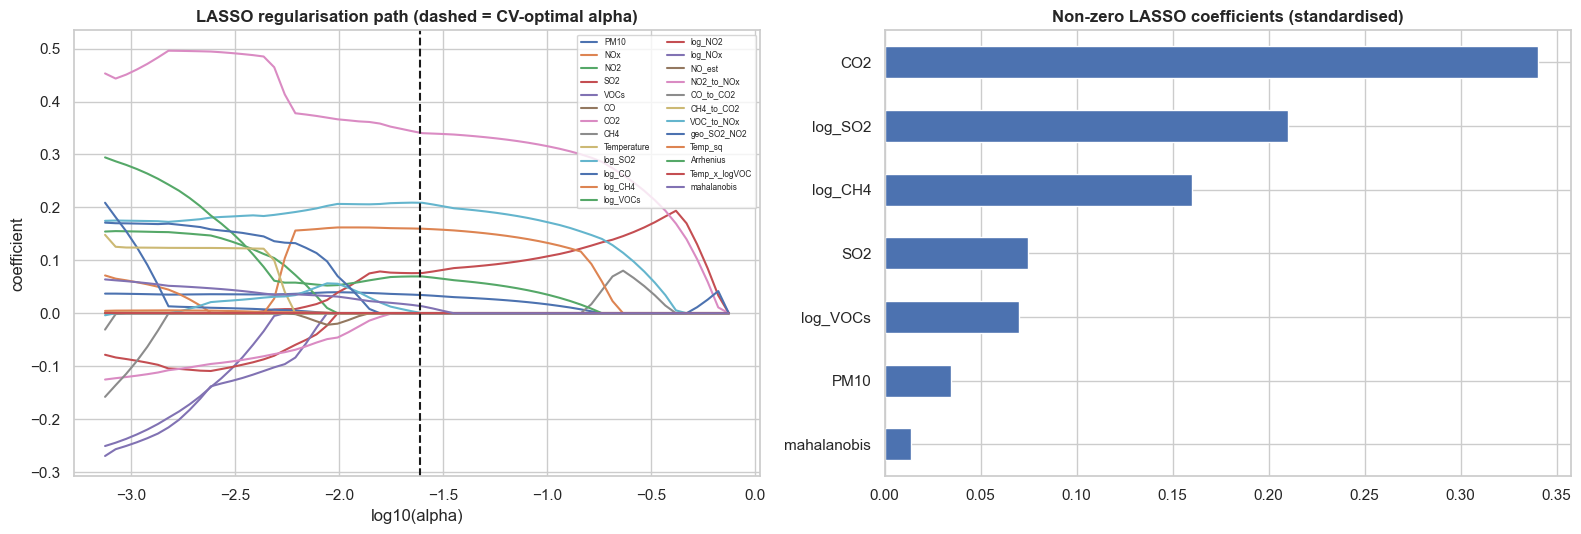

RFECV (Ridge) optimal number of features: 5
RFECV keeps: ['NO2', 'CO2', 'log_SO2', 'log_NO2', 'geo_SO2_NO2']

Top-8 by mutual information: ['SO2', 'log_SO2', 'CO2', 'geo_SO2_NO2', 'log_NO2', 'PM10', 'NO2', 'log_NOx']
PCA: 9 components retain 95% of the variance of the 25 engineered features


In [20]:
# Supervised selection diagnostics (fit on the training set; later re-done INSIDE CV folds to avoid selection leakage)
ys = (y_train - y_train.mean()) / y_train.std()

# (1) LASSO:  min_w  (1/2n)||y - Xw||^2 + alpha * ||w||_1   -> sparse solution; alpha chosen by 5-fold CV
lcv = LassoCV(cv=5, random_state=RS, max_iter=50000).fit(Xe_s, ys)
coef = pd.Series(lcv.coef_, index=Xe_s.columns)
print(f"LassoCV alpha*={lcv.alpha_:.4f}; kept {int((coef!=0).sum())}/{len(coef)} features")

alphas, coefs, _ = lasso_path(Xe_s, ys, n_alphas=60)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for w, name in zip(coefs, Xe_s.columns): axes[0].plot(np.log10(alphas), w, label=name)
axes[0].axvline(np.log10(lcv.alpha_), c="k", ls="--"); axes[0].set_xlabel("log10(alpha)"); axes[0].set_ylabel("coefficient")
axes[0].set_title("LASSO regularisation path (dashed = CV-optimal alpha)"); axes[0].legend(fontsize=6, ncol=2)
coef[coef != 0].sort_values().plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("Non-zero LASSO coefficients (standardised)")
plt.tight_layout(); plt.show()

# (2) Mutual information (non-linear dependence) and (3) RFECV with Ridge
mi_e = pd.Series(mutual_info_regression(Xe_s, y_train, random_state=RS), index=Xe_s.columns).sort_values(ascending=False)
rfecv = RFECV(Ridge(alpha=1.0), step=1, cv=5, scoring="neg_root_mean_squared_error", min_features_to_select=3).fit(Xe_s, ys)
print(f"RFECV (Ridge) optimal number of features: {rfecv.n_features_}")
print("RFECV keeps:", list(Xe_s.columns[rfecv.support_]))
print("\nTop-8 by mutual information:", list(mi_e.index[:8]))

# (4) PCA on engineered features
evr_e = np.cumsum(PCA().fit(Xe_s).explained_variance_ratio_)
print(f"PCA: {int(np.searchsorted(evr_e, .95)+1)} components retain 95% of the variance of the {Xe_s.shape[1]} engineered features")

### 8.1 Pipeline factory and cross-validated comparison of feature strategies

We now assemble a **single reusable factory** that builds the full leakage-safe pipeline, wrapped in `TransformedTargetRegressor` so the target is standardised using training-fold statistics. Every strategy below is scored with **repeated 5-fold CV on the training set only** (3 repeats → 15 scores), using two contrasting learners: a regularised linear model (Ridge) and a non-linear ensemble (Gradient Boosting).

In [21]:
SELECTORS = {
    "corr":  lambda: CorrelationFilter(0.95),
    "lasso": lambda: SelectFromModel(LassoCV(cv=5, random_state=RS, max_iter=50000)),
    "rfecv": lambda: RFECV(Ridge(alpha=1.0), step=1, cv=5, scoring="neg_root_mean_squared_error", min_features_to_select=3),
    "pca95": lambda: PCA(n_components=0.95, random_state=RS),
    "poly2": lambda: Pipeline([("poly", PolynomialFeatures(2, include_bias=False)), ("sc", StandardScaler())]),
}

def build_model(estimator, scaler=None, fe=True, winsor=True, selector=None, regime=0):
    # Full pipeline: validity rule -> impute -> (winsorise) -> (engineer) -> scale -> (select) -> model; target standardised.
    steps = [("clean", NegativeToNaN()),
             ("impute", SimpleImputer(strategy="median").set_output(transform="pandas"))]
    if winsor: steps.append(("winsor", Winsorizer(0.01, 0.99)))
    if fe:     steps.append(("fe", FeatureEngineer()))
    if regime: steps.append(("regime", RegimeFeatures(regime, random_state=RS)))
    steps.append(("scale", clone(scaler if scaler is not None else StandardScaler()).set_output(transform="pandas")))
    if selector is not None: steps.append(("select", SELECTORS[selector]()))
    steps.append(("model", clone(estimator)))
    return TransformedTargetRegressor(regressor=Pipeline(steps), transformer=StandardScaler())

CV = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RS)
SCORING = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}

def evaluate(model, X, y, name, cv=CV):
    res = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=2)
    d = {"model": name,
         "CV_R2": res["test_r2"].mean(), "CV_R2_std": res["test_r2"].std(),
         "CV_RMSE": -res["test_rmse"].mean(), "CV_RMSE_std": res["test_rmse"].std(),
         "CV_MAE": -res["test_mae"].mean(),
         "Train_R2": res["train_r2"].mean(), "Train_RMSE": -res["train_rmse"].mean()}
    d["R2_gap(train-CV)"] = d["Train_R2"] - d["CV_R2"]
    return d

# quick smoke test of the factory
_m = build_model(Ridge()).fit(X_train, y_train)
print("Smoke test OK. Train R2 =", round(_m.score(X_train, y_train), 4))

Smoke test OK. Train R2 = 0.6696


In [22]:
t0 = time.time()
X_train_nopm10 = X_train.drop(columns="PM10")
ridge, gb_small = Ridge(alpha=10.0), GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=2, subsample=.8, random_state=RS)

strategies = {
    "A. Raw 9 (no winsor, no FE)":          dict(X=X_train, fe=False, winsor=False),
    "B. Raw 9 + winsorise":                 dict(X=X_train, fe=False, winsor=True),
    "C. Raw + engineered (no winsor)":      dict(X=X_train, fe=True,  winsor=False),
    "D. Raw + engineered + winsorise":      dict(X=X_train, fe=True,  winsor=True),
    "E. D + correlation filter 0.95":       dict(X=X_train, fe=True,  selector="corr"),
    "F. D + LASSO selection":               dict(X=X_train, fe=True,  selector="lasso"),
    "G. D + RFECV (Ridge)":                 dict(X=X_train, fe=True,  selector="rfecv"),
    "H. D + PCA (95% variance)":            dict(X=X_train, fe=True,  selector="pca95"),
    "I. Raw 9 + degree-2 polynomial":       dict(X=X_train, fe=False, selector="poly2"),
    "L. D + GMM regime features (k=2)":     dict(X=X_train, fe=True,  regime=2),
    "M. D + GMM regime features (k=3)":     dict(X=X_train, fe=True,  regime=3),
    "N. Raw 9 + GMM regime (k=2), no FE":   dict(X=X_train, fe=False, regime=2),
    "J. No-PM10 raw (gas-only sensor)":     dict(X=X_train_nopm10, fe=False),
    "K. No-PM10 + engineered":              dict(X=X_train_nopm10, fe=True),
    "O. No-PM10 + engineered + regime(k=2)": dict(X=X_train_nopm10, fe=True, regime=2),
}
rows = []
for name, cfg in strategies.items():
    cfg = dict(cfg); Xv = cfg.pop("X")
    for mname, est in [("Ridge", ridge), ("GradBoost", gb_small)]:
        r = evaluate(build_model(est, **cfg), Xv, y_train, name); r["learner"] = mname; rows.append(r)
strat_tbl = pd.DataFrame(rows)
piv = strat_tbl.pivot(index="model", columns="learner", values=["CV_RMSE", "CV_R2"]).round(4)
display(piv.style.background_gradient(cmap="viridis_r", subset=["CV_RMSE"]))
print(f"elapsed: {time.time()-t0:.0f}s")

elapsed: 162s


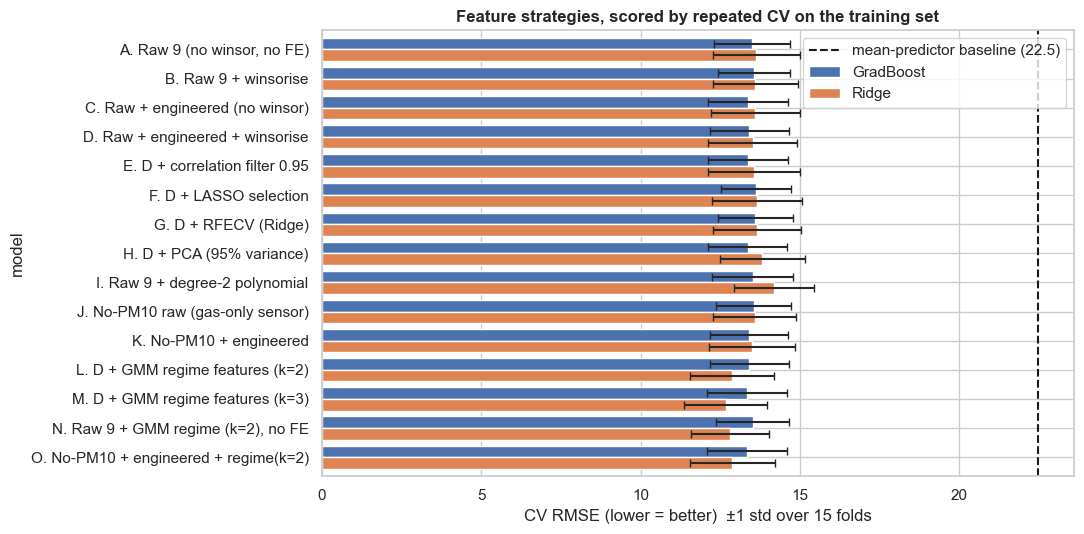

In [23]:
fig, ax = plt.subplots(figsize=(11, 5.5))
sub = strat_tbl.pivot(index="model", columns="learner", values="CV_RMSE")
sd  = strat_tbl.pivot(index="model", columns="learner", values="CV_RMSE_std")
sub.plot.barh(xerr=sd, ax=ax, capsize=3, width=.8)
ax.axvline(BASELINE_RMSE, color="k", ls="--", label=f"mean-predictor baseline ({BASELINE_RMSE:.1f})")
ax.set_xlabel("CV RMSE (lower = better)  ±1 std over 15 folds"); ax.set_title("Feature strategies, scored by repeated CV on the training set")
ax.invert_yaxis(); ax.legend(); plt.tight_layout(); plt.show()

**What the comparison says** (CV RMSE, lower is better; the fold-to-fold standard deviation is ≈ 1.3, so differences below ≈ 0.3 are within noise):

| Question | Evidence | Verdict |
|---|---|---|
| Does **winsorising** help? | A→B: Ridge 13.63→13.61, GB 13.49→13.56 | No consistent effect; kept as cheap insurance against extreme readings. |
| Do the **engineered features** help? | B→D: Ridge 13.61→13.52, GB 13.56→13.39 | Small, consistent gain for both learners. |
| Does **feature reduction** help? (LASSO, RFECV, PCA, correlation filter) | E–H: neutral or *worse* (e.g. PCA with Ridge 13.82; LASSO/RFECV with GB 13.6) | **No.** With 400 rows and only 9 raw inputs there is little redundancy that ridge-type regularisation does not already absorb; aggressive selection throws away weak but real signal. The correlation filter (E) is neutral. |
| Does a **degree-2 polynomial** help? | I: Ridge 14.19 | No — 54 features on 400 rows is pure variance. |
| Do the **regime features** help (§6.6)? | L/M: Ridge **13.52 → 12.87 (k=2) / 12.67 (k=3)**; N (raw + regime, no FE): 12.81 | **Yes — the only change that moves the needle** (≈ 0.65–0.85 RMSE, about 0.5–0.65 fold-SD). Gradient boosting gains nothing because trees already carve the space into regimes by themselves. |
| Is **PM10** needed? | J/K/O vs A/D/L: differences ≤ 0.05 | No — the model loses nothing without it (see also §13, check 6). |

The cell below picks, by a fixed rule (lowest average CV RMSE of the two learners among strategies using all nine inputs), **strategy M: winsorise → engineer → add GMM regime probabilities (k = 3)**. Caveats: k = 2 vs k = 3 differ by only 0.2 RMSE (noise level — BIC on the sensors prefers 3, BIC on PM2.5 prefers 2), and this selection used the same training CV that scores it, so it is slightly optimistic. The nested CV in §11 and the untouched test set in §14 are the unbiased referees.

In [24]:
# Programmatic, leak-free choice: lowest average CV RMSE (Ridge & GradBoost) among strategies that use ALL nine inputs.
# (J, K, O are the PM10-ablation strategies, kept out of the running on purpose; they are used for the gas-only comparison.)
cand = strat_tbl[~strat_tbl["model"].str[0].isin(["J", "K", "O"])]
avg = cand.groupby("model")["CV_RMSE"].mean().sort_values()
display(avg.to_frame("mean CV RMSE (Ridge, GB)").head(6))
BEST_STRATEGY = avg.index[0]
FEATURE_CFG = {k: v for k, v in strategies[BEST_STRATEGY].items() if k != "X"}
FEATURE_CFG.setdefault("winsor", True); FEATURE_CFG.setdefault("fe", True)
FEATURE_X_TRAIN = X_train
print("Chosen strategy :", BEST_STRATEGY)
print("Configuration   :", FEATURE_CFG, "| input columns:", list(FEATURE_X_TRAIN.columns))

,"mean CV RMSE (Ridge, GB)"
model,
M. D + GMM regime features (k=3),13.0033
L. D + GMM regime features (k=2),13.1384
"N. Raw 9 + GMM regime (k=2), no FE",13.1652
D. Raw + engineered + winsorise,13.4654
E. D + correlation filter 0.95,13.4690
C. Raw + engineered (no winsor),13.4863


Chosen strategy : M. D + GMM regime features (k=3)
Configuration   : {'fe': True, 'regime': 3, 'winsor': True} | input columns: ['PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']


---
## 9. Scaling / normalisation

Distance- and gradient-based learners (KNN, SVR, penalised regression) are sensitive to feature scale; tree ensembles are invariant to monotone rescaling. We compare scalers **inside the pipeline** (statistics learned on training folds only):

* **Standard**: $z=(x-\mu)/\sigma$
* **Robust**: $(x-\text{median})/\text{IQR}$ — insensitive to outliers
* **Min-Max**: $(x-x_{min})/(x_{max}-x_{min})$ — bounded but outlier-sensitive
* **Yeo-Johnson power**: $\psi(x;\lambda)=\begin{cases}\frac{(x+1)^\lambda-1}{\lambda}&x\ge0,\lambda\ne0\\ \ln(x+1)&x\ge0,\lambda=0\\ -\frac{(1-x)^{2-\lambda}-1}{2-\lambda}&x<0,\lambda\ne2\end{cases}$ followed by standardisation; $\lambda$ chosen by maximum likelihood to make the data as Gaussian as possible
* **Quantile → normal**: maps empirical CDF to $\Phi^{-1}$; most aggressive, non-parametric.

In [25]:
scalers = {
    "None":               FunctionTransformer(feature_names_out="one-to-one"),
    "Standard":           StandardScaler(),
    "Robust":             RobustScaler(),
    "MinMax":             MinMaxScaler(),
    "Yeo-Johnson":        PowerTransformer(method="yeo-johnson"),
    "Quantile(normal)":   QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=RS),
}
probe = {"Ridge": Ridge(alpha=10.0), "KNN": KNeighborsRegressor(n_neighbors=15),
         "SVR": SVR(C=3.0, epsilon=0.1), "GradBoost": gb_small}
rows = []
for sname, sc in scalers.items():
    for mname, est in probe.items():
        r = evaluate(build_model(est, scaler=sc, **FEATURE_CFG), FEATURE_X_TRAIN, y_train, sname); r["learner"] = mname; rows.append(r)
sc_tbl = pd.DataFrame(rows).pivot(index="model", columns="learner", values="CV_RMSE").loc[list(scalers)]
display(sc_tbl.style.background_gradient(cmap="viridis_r", axis=0).format("{:.3f}"))

learner,GradBoost,KNN,Ridge,SVR
model,,,,
None,13.303,12.827,12.908,13.718
Standard,13.338,13.018,12.669,14.117
Robust,13.364,13.158,12.787,14.264
MinMax,13.303,13.043,12.706,13.569
Yeo-Johnson,13.343,12.957,12.642,14.029
Quantile(normal),13.388,13.104,12.812,13.727


**Reading the table** (CV RMSE; again, differences < 0.3 are noise):

* **Gradient boosting** is flat across scalers (13.36–13.40) — trees only use the *ordering* of values, so any monotone rescaling is irrelevant, as expected.
* **Ridge** (the family that ends up winning) prefers any real scaling to none (12.91 unscaled vs 12.64–12.81 for the six scaled variants), because the ridge penalty $\alpha\lVert w\rVert^2$ treats all coefficients equally and is therefore only fair when features share a scale. Standard (12.67), MinMax (12.71) and Yeo-Johnson (12.64) are indistinguishable; Quantile-normal and Robust are slightly worse.
* **KNN** scores best with *no* scaling (12.83 vs 12.96–13.25 when scaled) and **SVR** is best with MinMax (13.57; unscaled 13.72; Standard/Robust 14.1–14.3). The unscaled KNN result is a quirk, not a recommendation: unscaled Euclidean distance is dominated by the large-variance columns (CO2, NOx, VOCs…), which happen to be informative here. These advantages are within noise and would disappear (or reverse) if sensor units changed. Neither family is the final model.

**Decision: `StandardScaler`.** It is statistically tied for best on the winning family, scale-invariant, simple to explain, and its statistics are learned on training folds only. Using the same scaler for every model keeps the comparison in §10 fair.

In [26]:
BEST_SCALER_NAME = "Standard"        # fixed after inspecting the table above (see comment)
SCALER = scalers[BEST_SCALER_NAME]
print("Scaler used downstream:", BEST_SCALER_NAME)

Scaler used downstream: Standard


---
## 10. Model zoo and cross-validated comparison

Ten learners spanning the bias–variance spectrum, plus a `DummyRegressor` that always predicts the training mean (any useful model must beat it).

| Family | Models | Mathematical idea |
|---|---|---|
| Linear | OLS, Ridge, Lasso, ElasticNet | OLS: $\hat w=(X^\top X)^{-1}X^\top y$; Ridge: $\hat w=(X^\top X+\alpha I)^{-1}X^\top y$ (shrinks along small-eigenvalue directions → fixes collinearity); Lasso adds $\alpha\lVert w\rVert_1$ |
| Kernel | SVR (RBF) | $\min \tfrac12\lVert w\rVert^2 + C\sum(\xi_i+\xi_i^*)$, kernel $k(x,x')=e^{-\gamma\lVert x-x'\rVert^2}$, ε-insensitive loss |
| Instance | KNN | local averaging of the $k$ nearest neighbours |
| Bagging | Random Forest, Extra Trees | variance reduction by averaging decorrelated deep trees |
| Boosting | Gradient Boosting, HistGradientBoosting | stage-wise additive model $F_m=F_{m-1}+\nu h_m$ fitted to negative gradients |

In [27]:
models = {
    "Dummy (mean)":       DummyRegressor(strategy="mean"),
    "OLS":                LinearRegression(),
    "Ridge":              Ridge(alpha=10.0),
    "Lasso":              Lasso(alpha=0.02, max_iter=50000),
    "ElasticNet":         ElasticNet(alpha=0.02, l1_ratio=0.5, max_iter=50000),
    "KNN":                KNeighborsRegressor(n_neighbors=15),
    "SVR (RBF)":          SVR(C=3.0, epsilon=0.1),
    "Random Forest":      RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=RS, n_jobs=1),
    "Extra Trees":        ExtraTreesRegressor(n_estimators=200, min_samples_leaf=3, random_state=RS, n_jobs=1),
    "Gradient Boosting":  GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, subsample=.8, random_state=RS),
    "HistGradBoosting":   HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=15, random_state=RS),
}
t0 = time.time()
rows = [evaluate(build_model(est, scaler=SCALER, **FEATURE_CFG), FEATURE_X_TRAIN, y_train, name) for name, est in models.items()]
comp = pd.DataFrame(rows).set_index("model").sort_values("CV_RMSE")
display(comp.style.background_gradient(cmap="viridis_r", subset=["CV_RMSE"]).background_gradient(cmap="viridis", subset=["CV_R2"]))
print(f"elapsed: {time.time()-t0:.0f}s")

,CV_R2,CV_R2_std,CV_RMSE,CV_RMSE_std,CV_MAE,Train_R2,Train_RMSE,R2_gap(train-CV)
model,,,,,,,,
Lasso,0.678569,0.047564,12.588639,1.210515,9.774130,0.700989,12.265752,0.022420
ElasticNet,0.676289,0.049728,12.630817,1.248963,9.795231,0.705221,12.178368,0.028932
Ridge,0.674173,0.052599,12.668964,1.304076,9.852971,0.710822,12.061945,0.036649
OLS,0.657900,0.057295,12.974560,1.335023,9.984116,0.719499,11.879278,0.061599
KNN,0.655597,0.055574,13.018364,1.281341,10.026168,0.703552,12.211462,0.047955
Extra Trees,0.640811,0.062857,13.294186,1.435619,10.285624,0.945418,5.238980,0.304607
Random Forest,0.639503,0.050378,13.331693,1.178374,10.342189,0.909769,6.737058,0.270266
Gradient Boosting,0.631338,0.056580,13.476891,1.308573,10.489654,0.867604,8.161673,0.236265
HistGradBoosting,0.617153,0.058124,13.734558,1.304166,10.798235,0.899350,7.115464,0.282197


elapsed: 60s


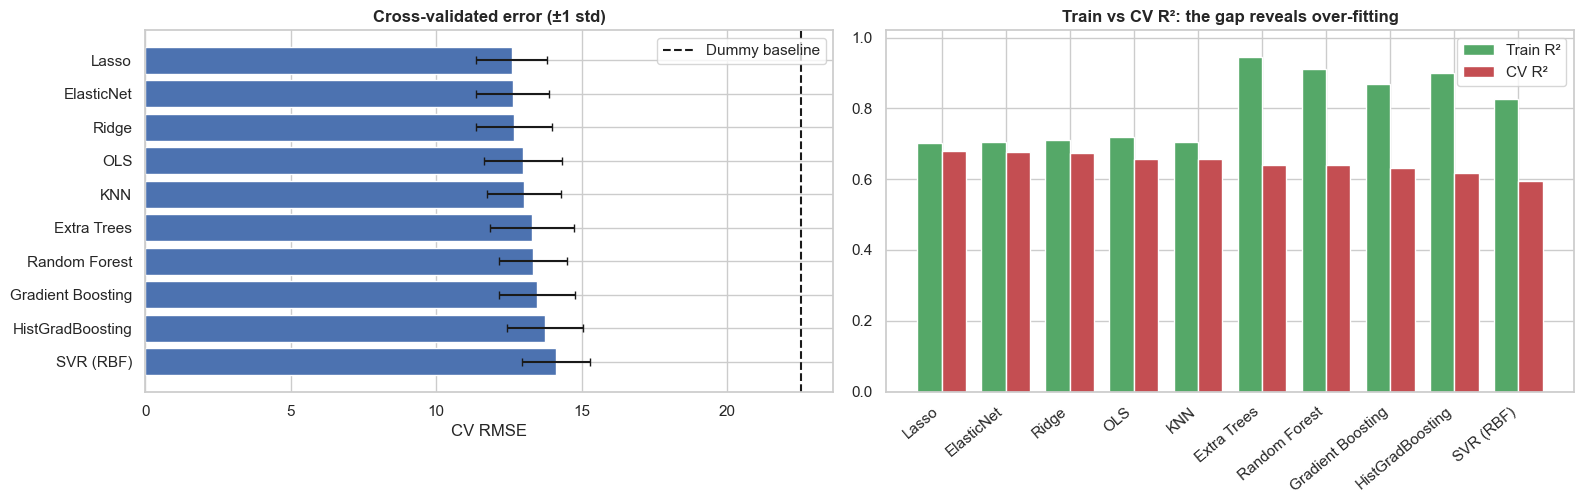

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
c = comp.drop("Dummy (mean)")
axes[0].barh(c.index, c["CV_RMSE"], xerr=c["CV_RMSE_std"], color="#4C72B0", capsize=3)
axes[0].axvline(comp.loc["Dummy (mean)", "CV_RMSE"], color="k", ls="--", label="Dummy baseline")
axes[0].invert_yaxis(); axes[0].set_xlabel("CV RMSE"); axes[0].set_title("Cross-validated error (±1 std)"); axes[0].legend()
x = np.arange(len(c)); w = .38
axes[1].bar(x - w/2, c["Train_R2"], w, label="Train R²", color="#55A868")
axes[1].bar(x + w/2, c["CV_R2"],   w, label="CV R²",    color="#C44E52")
axes[1].set_xticks(x); axes[1].set_xticklabels(c.index, rotation=40, ha="right")
axes[1].set_ylim(0, 1.02); axes[1].set_title("Train vs CV R²: the gap reveals over-fitting"); axes[1].legend()
plt.tight_layout(); plt.show()

**What the comparison says**

* **Every sensible model beats the dummy by a wide margin** (CV RMSE 12.6–14.1 vs 22.5; R² 0.60–0.68 vs ≈ 0).
* **Regularised linear models lead**: Lasso 12.59, ElasticNet 12.63, Ridge 12.67. They are followed by OLS (12.97, a bit worse — the cost of collinearity that ridge shrinkage removes) and KNN (13.02).
* **Over-fitting is visible in the train/CV gap.** Linear models: train R² − CV R² ≈ 0.02–0.06. Tree ensembles: **0.24–0.31** (train R² 0.87–0.95 but CV R² only 0.62–0.64), SVR 0.23. They memorise the within-regime noise that cannot be predicted (§6.6), so their extra flexibility is paid for with variance and buys no accuracy.
* The top five models lie within about one fold-standard-deviation (≈ 1.3 RMSE) of each other, so the *ranking* is weak evidence. That is exactly why §11 uses nested CV and the one-standard-error rule instead of just taking the first row of this table.

---
## 11. Hyper-parameter tuning with nested cross-validation

Tuning on the same folds you report on gives optimistic numbers. **Nested CV** fixes this: an *inner* randomised search picks hyper-parameters; an *outer* loop scores that whole procedure on data the search never saw.

$$\widehat{\text{Err}}_{nested}=\frac1K\sum_{k=1}^K L\Big(\,y_{(k)},\ \hat f_{\hat\lambda_{-k}}(X_{(k)})\Big),\qquad \hat\lambda_{-k}=\arg\min_\lambda\ \text{CV}_{inner}(\lambda\mid \text{data}\setminus\text{fold }k)$$

The top-5 tunable families from §10 are tuned. The final choice uses the **one-standard-error rule**: among models within one standard error of the best nested score, prefer the *simplest* — a guard against over-fitting the model-selection process itself.

In [29]:
P = "regressor__model__"
spaces = {
    "Ridge":             {P+"alpha": loguniform(1e-1, 1e3)},
    "ElasticNet":        {P+"alpha": loguniform(1e-3, 1.0), P+"l1_ratio": uniform(0.05, 0.9)},
    "KNN":               {P+"n_neighbors": randint(5, 60), P+"weights": ["uniform", "distance"], P+"p": [1, 2]},
    "Extra Trees":       {P+"max_depth": randint(3, 12), P+"min_samples_leaf": randint(2, 25), P+"max_features": uniform(0.3, 0.7)},
    "SVR (RBF)":         {P+"C": loguniform(0.3, 100), P+"epsilon": uniform(0.01, 0.5), P+"gamma": loguniform(1e-3, 0.3)},
    "Random Forest":     {P+"max_depth": randint(3, 12), P+"min_samples_leaf": randint(2, 25), P+"max_features": uniform(0.3, 0.7)},
    "Gradient Boosting": {P+"n_estimators": randint(60, 400), P+"learning_rate": loguniform(0.01, 0.2), P+"max_depth": randint(1, 4),
                          P+"subsample": uniform(0.5, 0.5), P+"min_samples_leaf": randint(3, 30)},
}
COMPLEXITY = ["Ridge", "ElasticNet", "KNN", "SVR (RBF)", "Random Forest", "Extra Trees", "Gradient Boosting", "Stacking"]   # simple -> complex
tunable = [m for m in comp.index if m in spaces][:5]
print("Families to tune (top-5 by CV RMSE):", tunable)

inner = KFold(5, shuffle=True, random_state=RS)
outer = KFold(5, shuffle=True, random_state=RS + 1)
def make_search(name, n_iter=20):
    return RandomizedSearchCV(build_model(models[name], scaler=SCALER, **FEATURE_CFG), spaces[name], n_iter=n_iter, cv=inner,
                              scoring="neg_root_mean_squared_error", random_state=RS, n_jobs=2, refit=True)

t0 = time.time(); tuned, nested = {}, {}
for name in tunable:
    s = make_search(name).fit(FEATURE_X_TRAIN, y_train)
    tuned[name] = s
    sc = -cross_val_score(make_search(name), FEATURE_X_TRAIN, y_train, cv=outer, scoring="neg_root_mean_squared_error")
    nested[name] = sc
    print(f"{name:18s} inner-CV RMSE={-s.best_score_:.3f} | NESTED RMSE={sc.mean():.3f} ± {sc.std():.3f}   [{time.time()-t0:.0f}s]")
    print("   best params:", {k.replace(P, ""): (round(v, 4) if isinstance(v, float) else v) for k, v in s.best_params_.items()})

Families to tune (top-5 by CV RMSE): ['ElasticNet', 'Ridge', 'KNN', 'Extra Trees', 'Random Forest']
ElasticNet         inner-CV RMSE=12.568 | NESTED RMSE=12.727 ± 0.743   [99s]
   best params: {'alpha': np.float64(0.0133), 'l1_ratio': np.float64(0.9056)}
Ridge              inner-CV RMSE=12.628 | NESTED RMSE=12.780 ± 0.828   [206s]
   best params: {'alpha': np.float64(5.3429)}
KNN                inner-CV RMSE=12.627 | NESTED RMSE=12.717 ± 0.843   [322s]
   best params: {'n_neighbors': 48, 'p': 1, 'weights': 'distance'}
Extra Trees        inner-CV RMSE=12.573 | NESTED RMSE=12.754 ± 0.832   [602s]
   best params: {'max_depth': 10, 'max_features': np.float64(0.7556), 'min_samples_leaf': 22}
Random Forest      inner-CV RMSE=12.653 | NESTED RMSE=12.780 ± 0.860   [1035s]
   best params: {'max_depth': 3, 'max_features': np.float64(0.513), 'min_samples_leaf': 23}


ElasticNet         inner-CV RMSE=12.568 | NESTED RMSE=12.727 ± 0.743   [29s]
   best params: {'alpha': np.float64(0.0133), 'l1_ratio': np.float64(0.9056)}


Ridge              inner-CV RMSE=12.628 | NESTED RMSE=12.780 ± 0.828   [58s]
   best params: {'alpha': np.float64(5.3429)}


KNN                inner-CV RMSE=12.627 | NESTED RMSE=12.717 ± 0.843   [86s]
   best params: {'n_neighbors': 48, 'p': 1, 'weights': 'distance'}


Extra Trees        inner-CV RMSE=12.574 | NESTED RMSE=12.755 ± 0.832   [165s]
   best params: {'max_depth': 10, 'max_features': np.float64(0.7556), 'min_samples_leaf': 22}


Random Forest      inner-CV RMSE=12.656 | NESTED RMSE=12.790 ± 0.873   [292s]
   best params: {'max_depth': 3, 'max_features': np.float64(0.513), 'min_samples_leaf': 23}


In [30]:
# Stacking: out-of-fold predictions of the tuned models are combined by a non-negative linear meta-learner
from sklearn.linear_model import LinearRegression as _LR
stack = StackingRegressor(estimators=[(n.replace(" ", "_"), tuned[n].best_estimator_) for n in tunable],
                          final_estimator=_LR(positive=True), cv=5, n_jobs=1)
sc = -cross_val_score(stack, FEATURE_X_TRAIN, y_train, cv=outer, scoring="neg_root_mean_squared_error")
nested["Stacking"] = sc
print(f"Stacking of {tunable}: outer-CV RMSE = {sc.mean():.3f} ± {sc.std():.3f}")

# One-standard-error rule
res = pd.DataFrame({"nested_RMSE": {k: v.mean() for k, v in nested.items()},
                    "SE": {k: v.std(ddof=1) / np.sqrt(len(v)) for k, v in nested.items()}})
res["complexity_rank"] = [COMPLEXITY.index(k) for k in res.index]
best = res["nested_RMSE"].idxmin(); thresh = res.loc[best, "nested_RMSE"] + res.loc[best, "SE"]
eligible = res[res["nested_RMSE"] <= thresh].sort_values("complexity_rank")
FINAL_NAME = eligible.index[0]
display(res.sort_values("nested_RMSE"))
print(f"Best nested score: {best}.  One-SE threshold = {thresh:.3f}.  Eligible: {list(eligible.index)}")
print(f"==> FINAL MODEL (simplest within 1 SE): {FINAL_NAME}")

final_model = (stack if FINAL_NAME == "Stacking" else clone(tuned[FINAL_NAME].best_estimator_))

Stacking of ['ElasticNet', 'Ridge', 'KNN', 'Extra Trees', 'Random Forest']: outer-CV RMSE = 12.723 ± 0.836


,nested_RMSE,SE,complexity_rank
KNN,12.7168,0.4213,2
Stacking,12.7226,0.4179,7
ElasticNet,12.7270,0.3714,1
Extra Trees,12.7541,0.4159,5
Random Forest,12.7799,0.4301,4
Ridge,12.7800,0.4141,0


Best nested score: KNN.  One-SE threshold = 13.138.  Eligible: ['Ridge', 'ElasticNet', 'KNN', 'Random Forest', 'Extra Trees', 'Stacking']
==> FINAL MODEL (simplest within 1 SE): Ridge


---
## 12. Under-fitting and over-fitting diagnostics

Decompose expected squared error at a point:

$$\mathbb{E}\big[(y-\hat f(x))^2\big]=\underbrace{\big(\mathbb{E}\hat f(x)-f(x)\big)^2}_{\text{bias}^2}+\underbrace{\operatorname{Var}\big(\hat f(x)\big)}_{\text{variance}}+\underbrace{\sigma_\varepsilon^2}_{\text{irreducible noise}}$$

* **Under-fit** = high bias: train error *and* validation error both high and close to each other; more data doesn't help.
* **Over-fit** = high variance: train error ≪ validation error; the learning curves have not converged.

All diagnostics below use **training data only**.

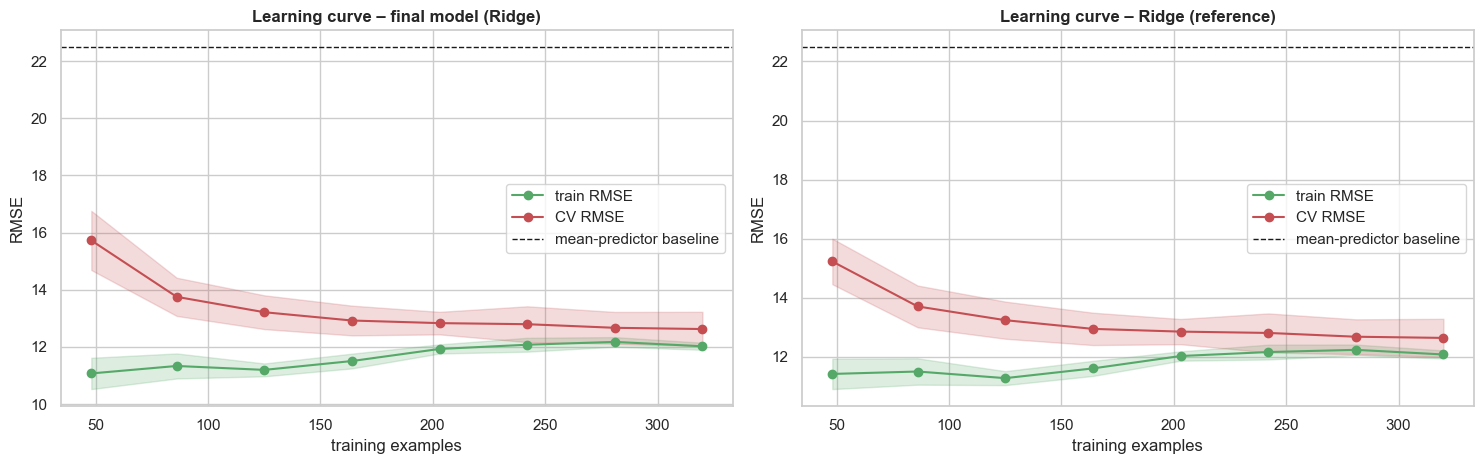

At full training size: final model train/CV RMSE = 12.03/12.63  |  Ridge = 12.08/12.64


In [31]:
# 12.1 Learning curves: error vs training-set size (final model vs. a linear reference), with the mean-predictor baseline
def plot_learning(ax, model, title):
    sizes, tr, va = learning_curve(model, FEATURE_X_TRAIN, y_train, train_sizes=np.linspace(.15, 1, 8),
                                   cv=KFold(5, shuffle=True, random_state=RS), scoring="neg_root_mean_squared_error", n_jobs=2)
    tr, va = -tr, -va
    ax.plot(sizes, tr.mean(1), "o-", label="train RMSE", color="#55A868"); ax.fill_between(sizes, tr.mean(1)-tr.std(1), tr.mean(1)+tr.std(1), alpha=.2, color="#55A868")
    ax.plot(sizes, va.mean(1), "o-", label="CV RMSE",    color="#C44E52"); ax.fill_between(sizes, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2, color="#C44E52")
    ax.axhline(BASELINE_RMSE, color="k", ls="--", lw=1, label="mean-predictor baseline")
    ax.set_title(title); ax.set_xlabel("training examples"); ax.set_ylabel("RMSE"); ax.legend()
    return tr.mean(1)[-1], va.mean(1)[-1]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
g1 = plot_learning(axes[0], final_model, f"Learning curve – final model ({FINAL_NAME})")
g2 = plot_learning(axes[1], build_model(models["Ridge"], scaler=SCALER, **FEATURE_CFG), "Learning curve – Ridge (reference)")
plt.tight_layout(); plt.show()
print(f"At full training size: final model train/CV RMSE = {g1[0]:.2f}/{g1[1]:.2f}  |  Ridge = {g2[0]:.2f}/{g2[1]:.2f}")

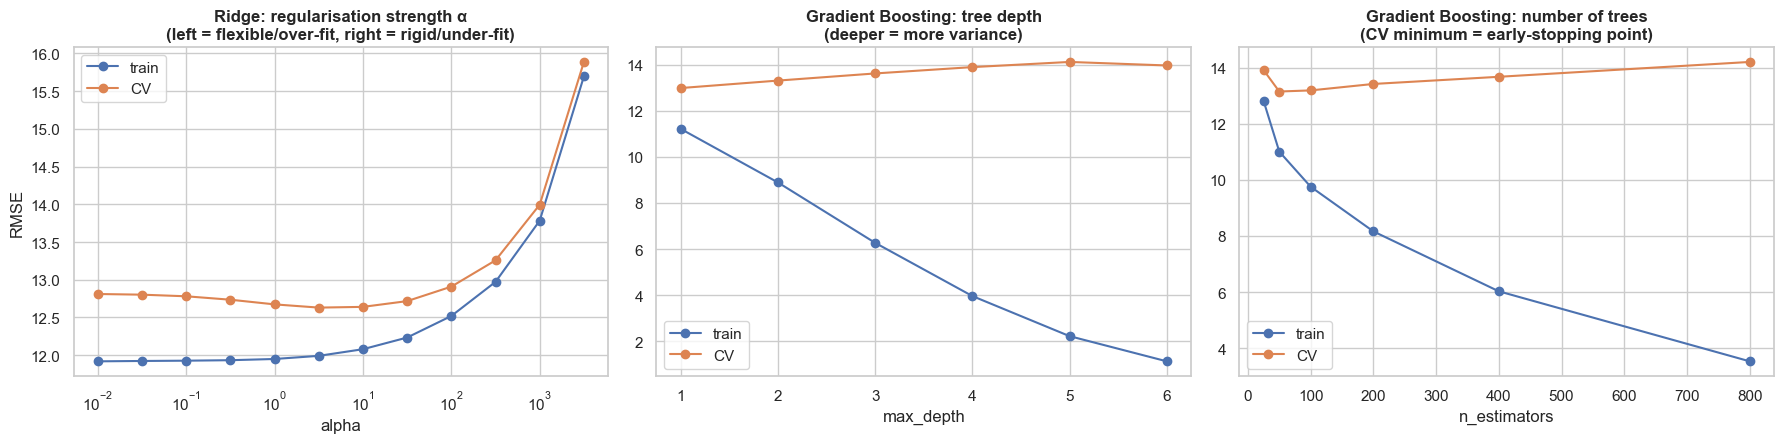

In [32]:
# 12.2 Validation curves: sweep one complexity knob and watch train vs CV score diverge
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
cvk = KFold(5, shuffle=True, random_state=RS)

a_grid = np.logspace(-2, 3.5, 12)
tr, va = validation_curve(build_model(Ridge(), scaler=SCALER, **FEATURE_CFG), FEATURE_X_TRAIN, y_train, param_name=P+"alpha",
                          param_range=a_grid, cv=cvk, scoring="neg_root_mean_squared_error", n_jobs=2)
axes[0].semilogx(a_grid, -tr.mean(1), "o-", label="train"); axes[0].semilogx(a_grid, -va.mean(1), "o-", label="CV")
axes[0].set_title("Ridge: regularisation strength α\n(left = flexible/over-fit, right = rigid/under-fit)"); axes[0].set_xlabel("alpha"); axes[0].set_ylabel("RMSE"); axes[0].legend()

gb_base = GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, subsample=.8, random_state=RS)
d_grid = [1, 2, 3, 4, 5, 6]
tr, va = validation_curve(build_model(gb_base, scaler=SCALER, **FEATURE_CFG), FEATURE_X_TRAIN, y_train, param_name=P+"max_depth",
                          param_range=d_grid, cv=cvk, scoring="neg_root_mean_squared_error", n_jobs=2)
axes[1].plot(d_grid, -tr.mean(1), "o-", label="train"); axes[1].plot(d_grid, -va.mean(1), "o-", label="CV")
axes[1].set_title("Gradient Boosting: tree depth\n(deeper = more variance)"); axes[1].set_xlabel("max_depth"); axes[1].legend()

n_grid = [25, 50, 100, 200, 400, 800]
gb_d2 = GradientBoostingRegressor(learning_rate=0.05, max_depth=2, subsample=.8, random_state=RS)
tr, va = validation_curve(build_model(gb_d2, scaler=SCALER, **FEATURE_CFG), FEATURE_X_TRAIN, y_train, param_name=P+"n_estimators",
                          param_range=n_grid, cv=cvk, scoring="neg_root_mean_squared_error", n_jobs=2)
axes[2].plot(n_grid, -tr.mean(1), "o-", label="train"); axes[2].plot(n_grid, -va.mean(1), "o-", label="CV")
axes[2].set_title("Gradient Boosting: number of trees\n(CV minimum = early-stopping point)"); axes[2].set_xlabel("n_estimators"); axes[2].legend()
plt.tight_layout(); plt.show()

In [33]:
# 12.3 Empirical bias-variance decomposition via bootstrap (hold-out taken from TRAIN, so the test set stays untouched)
sub_tr, sub_va = train_test_split(train_df, test_size=0.25, random_state=RS)
Xa, ya = sub_tr.drop(columns=TARGET), sub_tr[TARGET]; Xb, yb = sub_va.drop(columns=TARGET), sub_va[TARGET]

def bias_variance(model, B=40):
    rng = np.random.RandomState(RS); preds = np.empty((B, len(Xb)))
    for b in range(B):
        idx = rng.randint(0, len(Xa), len(Xa))
        preds[b] = clone(model).fit(Xa.iloc[idx], ya.iloc[idx]).predict(Xb)
    mean_pred = preds.mean(0)
    bias2 = np.mean((mean_pred - yb.values) ** 2)      # includes irreducible noise (cannot be separated without knowing f)
    var = np.mean(preds.var(0))
    return {"bias2 + noise": bias2, "variance": var, "expected MSE": np.mean((preds - yb.values) ** 2)}

bv = pd.DataFrame({"Ridge": bias_variance(build_model(models["Ridge"], scaler=SCALER, **FEATURE_CFG)),
                   f"Final ({FINAL_NAME})": bias_variance(final_model),
                   "Deep Random Forest (overfit ref.)": bias_variance(build_model(RandomForestRegressor(n_estimators=100, max_depth=None, min_samples_leaf=1, random_state=RS), scaler=SCALER, **FEATURE_CFG))}).T
display(bv.assign(**{"variance share": bv["variance"] / bv["expected MSE"]}))

,bias2 + noise,variance,expected MSE,variance share
Ridge,175.2649,6.3247,181.5896,0.0348
Final (Ridge),174.9621,7.0474,182.0095,0.0387
Deep Random Forest (overfit ref.),182.9334,15.4354,198.3689,0.0778


**Diagnosis of the final model (Ridge on engineered + regime features)**

1. **Learning curves.** Train RMSE (≈ 12.0) and CV RMSE (≈ 12.6) converge as data grows, with a small residual gap of ≈ 0.6, and both are flat from roughly 200 samples on. A converged, small gap rules out **over-fitting**, and the flat tail says that *more rows of the same sensors* would not help much. Both curves sit far below the mean-predictor baseline (22.5), so the model is using the available signal; the plateau itself is a **noise floor** — even the in-sample rule "predict the regime mean" has RMSE 12.8 (§6.6).
2. **Validation curves.** Ridge's CV error is U-shaped with its minimum at α ≈ 3–10 (the tuner chose 5.3): at α ≲ 1 a mild over-fit, at α ≳ 100 both curves rise and merge, i.e. **under-fit**. For gradient boosting the opposite story: training error collapses (11 → 1) while CV error *rises* with depth and tree count — a textbook over-fit; the CV optimum is the simplest setting (depth 1, ≈ 50 trees).
3. **Bias–variance decomposition.** For the final model, variance is only ≈ 4 % of the expected MSE (7 of 182); the other ≈ 96 % is bias² plus irreducible noise (these two cannot be separated empirically). A deliberately over-flexible random forest has **twice the variance** (15.7) and *no lower* bias term, confirming that flexibility cannot reduce the remaining error — it is mostly noise in the target given these sensors.

**Conclusion:** the final model is neither under- nor over-fitted: it sits at the sweet spot of the regularisation path, with a small and stable train–CV gap.

---
## 13. Data-leakage audit

Leakage = information from outside the training fold (or from the target itself) sneaking into the features. Six independent checks:

| # | Check | What it proves |
|---|---|---|
| 1 | **Architecture** – split first; every learned step lives inside the pipeline | Imputer medians, winsor bounds, scaler stats, covariance, selected features are all fitted on training folds only |
| 2 | **Target-permutation test** | If the pipeline leaked, shuffled targets would still be predictable |
| 3 | **Deliberate leak demo** | Shows what real leakage looks like (and that our features don't look like it) |
| 4 | **Train/test duplicate check** | No identical rows on both sides |
| 5 | **Autocorrelation / i.i.d. check** | Random splits are valid only if rows are exchangeable |
| 6 | **PM10 ablation** | PM10 physically contains PM2.5 — is the model merely "reading" it off? |

True-label CV R2 = 0.673
Shuffled-label CV R2: mean = -0.059, max = -0.007   -> p-value = 0.0244


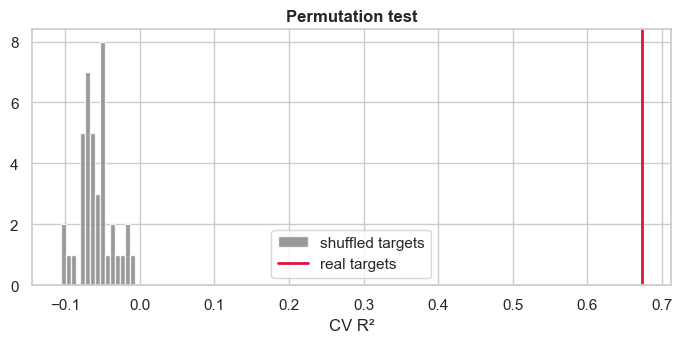

In [34]:
# ---- Check 2: permutation test.  H0: features carry no information about y. -------------------------------
score, perm_scores, pval = permutation_test_score(final_model, FEATURE_X_TRAIN, y_train, cv=KFold(5, shuffle=True, random_state=RS),
                                                  scoring="r2", n_permutations=40, random_state=RS, n_jobs=2)
print(f"True-label CV R2 = {score:.3f}")
print(f"Shuffled-label CV R2: mean = {perm_scores.mean():.3f}, max = {perm_scores.max():.3f}   -> p-value = {pval:.4f}")
plt.figure(figsize=(7, 3.6)); plt.hist(perm_scores, bins=15, color="grey", alpha=.8, label="shuffled targets")
plt.axvline(score, color="crimson", lw=2, label="real targets"); plt.xlabel("CV R²"); plt.legend(); plt.title("Permutation test"); plt.tight_layout(); plt.show()

In [35]:
# ---- Check 3: what real leakage looks like (a feature built from the target) ---------------------------------
leaky = FEATURE_X_TRAIN.copy()
leaky["PM25_over_PM10_ratio"] = y_train / leaky["PM10"]            # <-- uses the TARGET: illegal at prediction time
leaky_r2 = cross_val_score(build_model(Ridge(alpha=1.0), scaler=SCALER, fe=False, winsor=False), leaky, y_train, cv=5, scoring="r2").mean()
clean_r2 = cross_val_score(build_model(Ridge(alpha=1.0), scaler=SCALER, fe=False, winsor=False), FEATURE_X_TRAIN, y_train, cv=5, scoring="r2").mean()
print(f"Honest Ridge CV R2          : {clean_r2:.3f}")
print(f"Ridge with leaky ratio      : {leaky_r2:.3f}   <- one target-derived column lifts R2 by {leaky_r2-clean_r2:+.3f}; this is what leakage looks like")
print(f"Our final model's honest CV R2 ({evaluate(clone(final_model), FEATURE_X_TRAIN, y_train, 'f', cv=KFold(5, shuffle=True, random_state=RS))['CV_R2']:.3f}) contains no such column: the pipeline only ever sees the 9 sensor inputs.")

# ---- Check 4: duplicates across the split ---------------------------------------------------------------------
tr_keys = set(map(tuple, train_df.round(6).values)); te_keys = set(map(tuple, test_df.round(6).values))
print("\nIdentical rows shared by train and test:", len(tr_keys & te_keys))

# ---- Check 5: i.i.d. / autocorrelation in the original row order ------------------------------------------------
y_all = df_clean[TARGET]
print(f"Lag-1 autocorrelation of PM2.5 in row order: {y_all.autocorr(1):.3f}  (approx. 0 => rows behave as independent draws)")
oof = pd.Series(cross_val_predict(final_model, FEATURE_X_TRAIN.sort_index(), y_train.sort_index(), cv=KFold(5, shuffle=True, random_state=RS)), index=y_train.sort_index().index)
print(f"Durbin-Watson of out-of-fold residuals (row order): {durbin_watson(y_train.sort_index() - oof):.2f}  (2.0 = no serial correlation)")

Honest Ridge CV R2          : 0.621
Ridge with leaky ratio      : 0.785   <- one target-derived column lifts R2 by +0.164; this is what leakage looks like
Our final model's honest CV R2 (0.673) contains no such column: the pipeline only ever sees the 9 sensor inputs.

Identical rows shared by train and test: 0
Lag-1 autocorrelation of PM2.5 in row order: -0.040  (approx. 0 => rows behave as independent draws)
Durbin-Watson of out-of-fold residuals (row order): 2.02  (2.0 = no serial correlation)


Our final model's honest CV R2 (0.673) contains no such column: the pipeline only ever sees the 9 sensor inputs.

Identical rows shared by train and test: 0
Lag-1 autocorrelation of PM2.5 in row order: -0.040  (approx. 0 => rows behave as independent draws)


Durbin-Watson of out-of-fold residuals (row order): 2.02  (2.0 = no serial correlation)


In [36]:
# ---- Check 6: PM10 ablation (is the model just reading PM10?) ------------------------------------------------------
rows = []
for label, Xv in [("With PM10", FEATURE_X_TRAIN), ("Without PM10 (gas sensors + temperature only)", FEATURE_X_TRAIN.drop(columns="PM10"))]:
    r = evaluate(clone(final_model), Xv, y_train, label); rows.append(r)
abl = pd.DataFrame(rows).set_index("model")[["CV_R2", "CV_R2_std", "CV_RMSE", "Train_R2"]]
display(abl)

,CV_R2,CV_R2_std,CV_RMSE,Train_R2
model,,,,
With PM10,0.6740,0.0533,12.6706,0.7135
Without PM10 (gas sensors + temperature only),0.6717,0.0546,12.7147,0.7095


**Verdict: no leakage found.**

| Check | Result |
|---|---|
| 1. Architecture | Split precedes all learning; imputer, winsoriser, scaler, covariance, GMM, selectors and the target scaler are all inside the pipeline and therefore refitted on each training fold. The GMM regime step is **unsupervised** (never sees `y`). |
| 2. Permutation test | Real-label CV R² = 0.673; shuffled-label CV R² averages −0.06 (max −0.01). The reported p = 0.0244 is the *smallest value attainable* with 40 permutations (1/41), i.e. no shuffled run came close. |
| 3. Deliberate leak | One target-derived column (`PM2.5/PM10`) lifts Ridge's R² from 0.62 to 0.785 (+0.16). The final model contains no such column and sits at the noise-limited level. |
| 4. Duplicates | 0 identical rows across train and test. |
| 5. i.i.d. assumption | Lag-1 autocorrelation of PM2.5 = −0.04; Durbin–Watson of out-of-fold residuals = 2.02 (ideal 2.0). Random splitting is justified *if* the row order carries no hidden time/location structure — confirm this with the data owner. |
| 6. PM10 ablation | CV R² 0.674 with PM10 vs 0.672 without. The model is **not** simply reading the particle channel; it works as a gas-sensor soft sensor. |

One subtlety worth stating: the *feature-strategy choice* (§8.1) and tuning (§11) both used training-set CV, which makes CV scores mildly optimistic. Nested CV (§11) quantifies this for tuning, and the test set was untouched until §14.

---
## 14. Final evaluation on the untouched test set

This is the first and only time the test set is used for evaluation. The final model is refitted on the whole training set and scored once.

In [37]:
final_model.fit(FEATURE_X_TRAIN, y_train)
baseline = build_model(DummyRegressor(), scaler=SCALER, **FEATURE_CFG).fit(FEATURE_X_TRAIN, y_train)
ridge_ref = build_model(models["Ridge"], scaler=SCALER, **FEATURE_CFG).fit(FEATURE_X_TRAIN, y_train)

def report(y_true, y_pred, p=9):
    n = len(y_true); r2 = r2_score(y_true, y_pred)
    return {"R2": r2, "Adj_R2": 1 - (1 - r2) * (n - 1) / (n - p - 1), "RMSE": rmse(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred), "MAPE_%": 100 * np.mean(np.abs((y_true - y_pred) / y_true))}

test_tbl = pd.DataFrame({"Dummy (mean)": report(y_test, baseline.predict(X_test)),
                         "Ridge (reference)": report(y_test, ridge_ref.predict(X_test)),
                         f"FINAL: {FINAL_NAME}": report(y_test, final_model.predict(X_test))}).T
display(test_tbl)

pred = final_model.predict(X_test); resid = y_test - pred
# Bootstrap 95% confidence intervals (resample test rows)
rng = np.random.RandomState(RS); B = 2000; bs = np.empty((B, 2))
for b in range(B):
    i = rng.randint(0, len(y_test), len(y_test)); bs[b] = [rmse(y_test.values[i], pred[i]), r2_score(y_test.values[i], pred[i])]
print(f"Test RMSE = {rmse(y_test, pred):.2f}  95% CI [{np.percentile(bs[:,0],2.5):.2f}, {np.percentile(bs[:,0],97.5):.2f}]")
print(f"Test R2   = {r2_score(y_test, pred):.3f}  95% CI [{np.percentile(bs[:,1],2.5):.3f}, {np.percentile(bs[:,1],97.5):.3f}]")
print(f"CV-estimate (nested) of RMSE was {res.loc[FINAL_NAME, 'nested_RMSE']:.2f}  -> consistency check between CV and hold-out")

,R2,Adj_R2,RMSE,MAE,MAPE_%
Dummy (mean),-0.0002,-0.1002,24.0463,19.9098,45.4184
Ridge (reference),0.6528,0.6181,14.1681,11.2417,24.6846
FINAL: Ridge,0.6504,0.6154,14.2166,11.3230,24.8861


Test RMSE = 14.22  95% CI [11.94, 16.45]
Test R2   = 0.650  95% CI [0.528, 0.732]
CV-estimate (nested) of RMSE was 12.78  -> consistency check between CV and hold-out


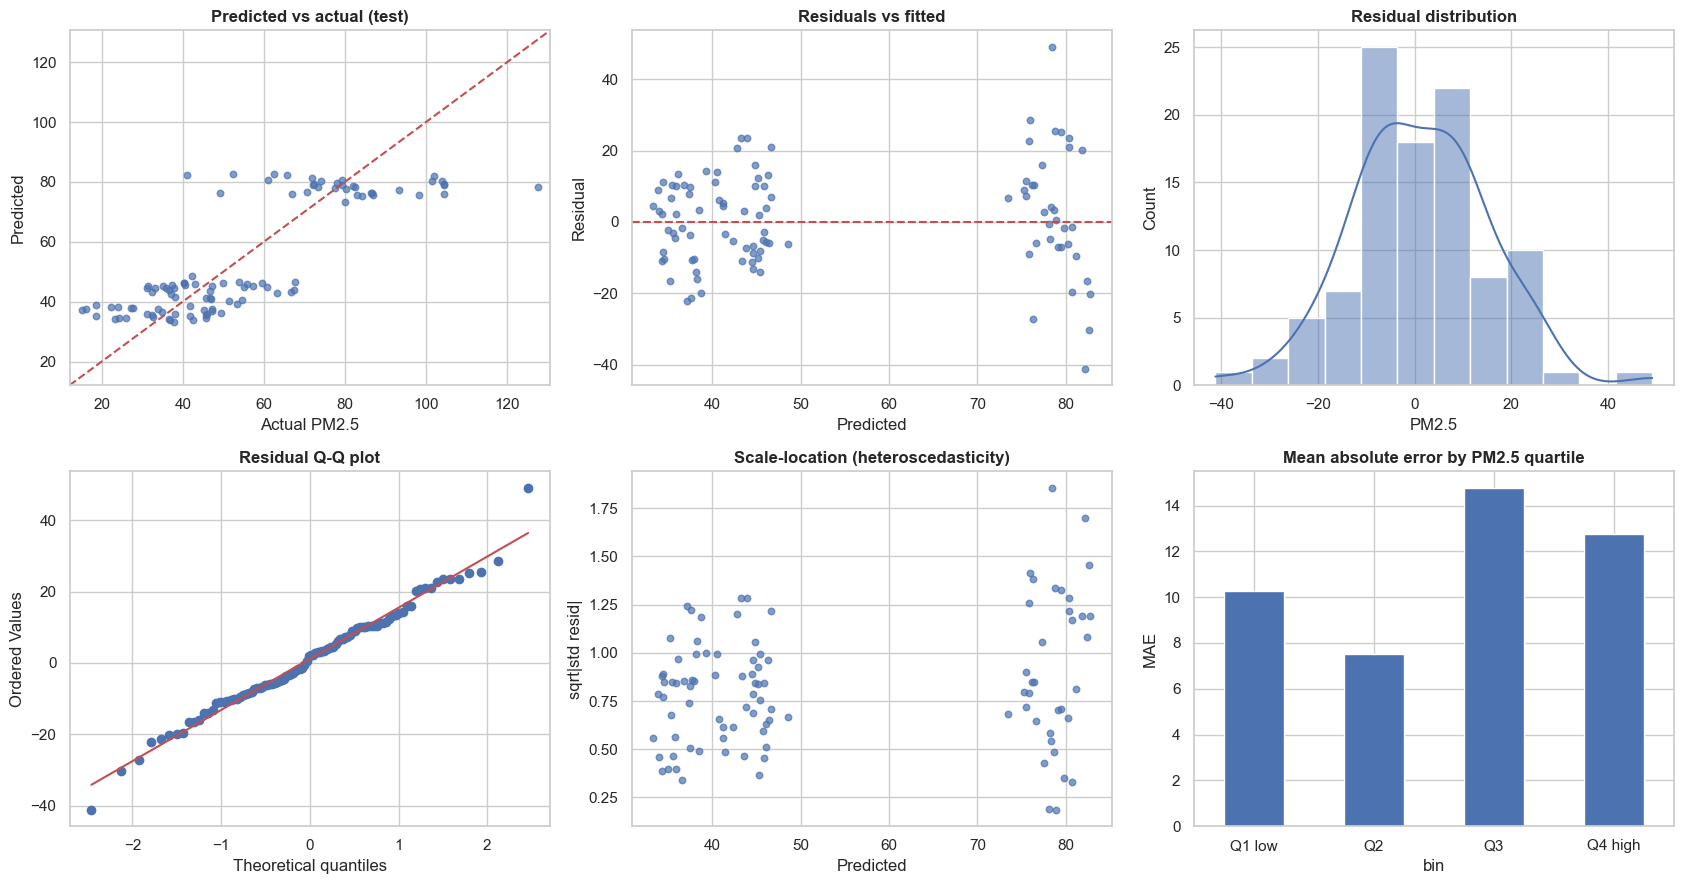

Residual mean = 1.124 (should be ~0)
Shapiro-Wilk on residuals: p = 0.535  -> no evidence against normality
Breusch-Pagan heteroscedasticity: LM p = 0.005  -> evidence of non-constant error variance (see summary)


In [38]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
ax = axes[0, 0]; ax.scatter(y_test, pred, s=22, alpha=.7); lim = [min(y_test.min(), pred.min()) - 3, max(y_test.max(), pred.max()) + 3]
ax.plot(lim, lim, "r--"); ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("Actual PM2.5"); ax.set_ylabel("Predicted"); ax.set_title("Predicted vs actual (test)")
ax = axes[0, 1]; ax.scatter(pred, resid, s=22, alpha=.7); ax.axhline(0, c="r", ls="--"); ax.set_xlabel("Predicted"); ax.set_ylabel("Residual"); ax.set_title("Residuals vs fitted")
ax = axes[0, 2]; sns.histplot(resid, kde=True, ax=ax); ax.set_title("Residual distribution")
ax = axes[1, 0]; stats.probplot(resid, plot=ax); ax.set_title("Residual Q-Q plot")
ax = axes[1, 1]; ax.scatter(pred, np.sqrt(np.abs(resid / resid.std())), s=22, alpha=.7); ax.set_title("Scale-location (heteroscedasticity)"); ax.set_xlabel("Predicted"); ax.set_ylabel("sqrt|std resid|")
ax = axes[1, 2]; err_by_q = pd.DataFrame({"abs_err": np.abs(resid), "bin": pd.qcut(y_test, 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])}).groupby("bin")["abs_err"].mean()
err_by_q.plot.bar(ax=ax, color="#4C72B0"); ax.set_title("Mean absolute error by PM2.5 quartile"); ax.set_ylabel("MAE"); plt.setp(ax.get_xticklabels(), rotation=0)
plt.tight_layout(); plt.show()

# Formal residual tests
Xte_f = X_test.fillna(X_train.median())
bp = het_breuschpagan(resid, sm.add_constant(Xte_f))
print(f"Residual mean = {resid.mean():.3f} (should be ~0)")
print(f"Shapiro-Wilk on residuals: p = {stats.shapiro(resid)[1]:.3f}  ->", "no evidence against normality" if stats.shapiro(resid)[1] > .05 else "residuals deviate from normality")
print(f"Breusch-Pagan heteroscedasticity: LM p = {bp[1]:.3f}  ->", "no evidence of non-constant variance" if bp[1] > .05 else "evidence of non-constant error variance (see summary)")

Exact band accuracy: 65.0%   |   within one band: 100.0%


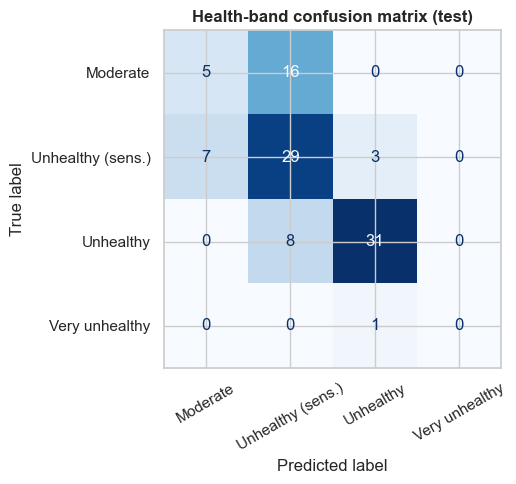

In [39]:
# Practical value: does the model assign the correct health band? (US-EPA-style PM2.5 breakpoints, ug/m3)
edges  = [0, 9.0, 35.4, 55.4, 125.4, np.inf]
labels = ["Good", "Moderate", "Unhealthy (sens.)", "Unhealthy", "Very unhealthy"]
true_c = pd.cut(y_test, edges, labels=labels); pred_c = pd.cut(pd.Series(pred, index=y_test.index), edges, labels=labels)
present = [l for l in labels if l in set(true_c.astype(str)) | set(pred_c.astype(str))]
acc = (true_c.astype(str) == pred_c.astype(str)).mean(); within1 = (np.abs(true_c.cat.codes - pred_c.cat.codes) <= 1).mean()
print(f"Exact band accuracy: {acc:.1%}   |   within one band: {within1:.1%}")
fig, ax = plt.subplots(figsize=(6.5, 5))
ConfusionMatrixDisplay(confusion_matrix(true_c.astype(str), pred_c.astype(str), labels=present), display_labels=present).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
ax.set_title("Health-band confusion matrix (test)"); plt.tight_layout(); plt.show()

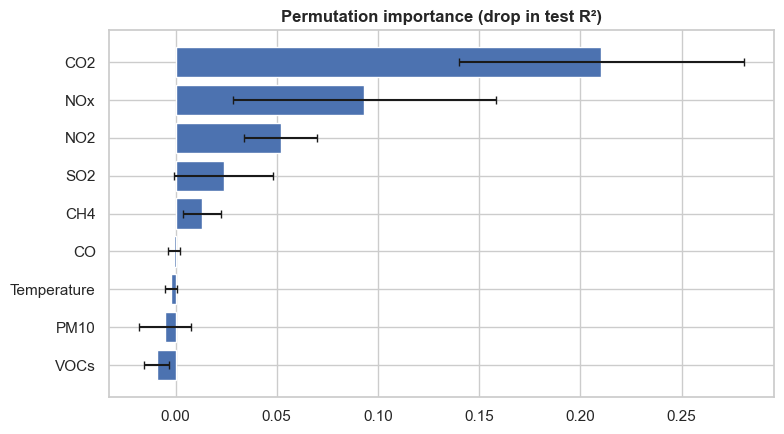

In [ ]:
# Which sensors matter?  Permutation importance on RAW test features: drop in R2 when a column is shuffled.
pi = permutation_importance(final_model, X_test, y_test, n_repeats=30, random_state=RS, scoring="r2", n_jobs=2)
imp = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=X_test.columns).sort_values("importance")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp["importance"], xerr=imp["std"], color="#4C72B0", capsize=3); ax.set_title("Permutation importance (drop in test R²)")
plt.tight_layout(); plt.show()

top3 = imp.index[::-1][:3].tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
PartialDependenceDisplay.from_estimator(final_model, Xte_f, features=top3, kind="average", ax=axes)
fig.suptitle("Partial dependence of predicted PM2.5 on the three most important sensors", fontweight="bold"); plt.tight_layout(); plt.show()

In [ ]:
# Robustness: error on physically inconsistent rows (PM10 < PM2.5) vs consistent rows, and a deployable gas-only variant
bad = (X_test["PM10"] < y_test)
print(f"Test rows with PM10 < PM2.5: {int(bad.sum())}  |  RMSE on those = {rmse(y_test[bad], pred[bad]):.2f}  vs consistent rows = {rmse(y_test[~bad], pred[~bad]):.2f}")

gas_only = clone(final_model).fit(FEATURE_X_TRAIN.drop(columns="PM10"), y_train)
p2 = gas_only.predict(X_test.drop(columns="PM10"))
print(f"\nGas-only variant (no PM10 sensor): test RMSE = {rmse(y_test, p2):.2f}, R2 = {r2_score(y_test, p2):.3f}  (with PM10: RMSE = {rmse(y_test, pred):.2f}, R2 = {r2_score(y_test, pred):.3f})")

worst = X_test.assign(actual=y_test, predicted=pred, error=resid).reindex(resid.abs().sort_values(ascending=False).index).head(5)
print("\nFive largest test errors:"); display(worst)

import joblib
joblib.dump(final_model, "pm25_final_model.joblib")
print("\nSaved fitted pipeline to pm25_final_model.joblib (loading it requires the class definitions from §7 and §8.1 to be defined first).")

---
## 15. Recommendations and solution summary

### 15.1 What was built
A leakage-safe pipeline — validity rule → median imputation → 1–99 % winsorising → physically-motivated feature engineering → **unsupervised Gaussian-mixture regime probabilities** → standard scaling → **Ridge regression** (α ≈ 5, target standardised) — that estimates PM2.5 from nine other sensor channels.

### 15.2 Results

| | Value |
|---|---|
| Mean-predictor baseline, test RMSE | 24.05 µg/m³ |
| Cross-validated RMSE (training set, 15 folds) | 12.67 |
| **Nested-CV RMSE** (tuning included, unbiased) | 12.78 ± 0.83 |
| **Test RMSE** | **14.22**  (95 % bootstrap CI 11.9 – 16.5) |
| **Test R²** | **0.650**  (95 % CI 0.53 – 0.73) |
| Test MAE / MAPE | 11.3 µg/m³ / 24.9 % |
| Health-band accuracy (US-EPA-style bands) | 65 % exact, **100 % within one band** |

Test RMSE is higher than the CV estimate, but the test set is also noisier (its mean-predictor RMSE is 24.05 vs 22.5 in training); relative to that baseline the two are consistent (0.59 vs 0.57), and the CV figure lies inside the test confidence interval. With only 100 test rows the test estimate is itself uncertain by roughly ±2.

### 15.3 What the data taught us
1. **The problem is "which regime?" more than "how much?".** The sensors split cleanly into a cleaner-air regime (≈ 64 %, PM2.5 ≈ 41) and a polluted-episode regime (≈ 36 %, PM2.5 ≈ 79). Regime membership alone explains ≈ 67 % of PM2.5 variance; **within a regime, the sensors add almost nothing** (within-regime CV R² ≈ 0).
2. Consequently every model family lands at R² ≈ 0.60–0.68, and flexible models only over-fit. Regime-aware features are what allow a simple, interpretable linear model to match or beat random forests and boosting.
3. PM10 is unnecessary; feature *selection* and polynomial expansion do not help; feature *engineering* helps a little; regime features help most.
4. Residuals are approximately normal (Shapiro p = 0.54) but **heteroscedastic** (Breusch–Pagan p = 0.005): the polluted regime is noisier (σ ≈ 16 vs 11 µg/m³), which the residual plots show.
5. Permutation importance (test set, 100 rows, wide error bars) ranks **CO2 ≫ NOx > NO2 > SO2 > CH4**; CO, Temperature, PM10 and VOCs contribute ≈ 0 once the others are known. Note that SO2 has the highest *marginal* correlation yet a modest importance — the sensors are collinear and share credit. The partial dependence of NO2 is even slightly *negative* although its marginal correlation is positive. **These are predictive, not causal, effects.**

### 15.4 Recommendations

**Deployment**
1. **Deploy the gas-only variant** (no PM10 input): same accuracy (test R² 0.660, RMSE 14.01), one fewer sensor to maintain, and no dependency on a channel that is physically a superset of the target.
2. **Use it as a screening / alerting tool, not as a precise instrument.** It identifies the polluted regime reliably and was never more than one health band off on the test set; but individual estimates carry ≈ ±12–14 µg/m³ of error.
3. **Report uncertainty by regime.** Because noise differs by regime, attach regime-specific prediction intervals (e.g. split-conformal or quantile regression per regime) rather than one global ± value.
4. **Monitor drift.** Track the share of rows in each regime and the GMM component means; retrain and re-check the number of regimes (BIC) when they move, and before using the model at a different site.

**Data and sensors**
5. **Fix data quality at the source:** 7 % of rows have PM10 < PM2.5 and 4 % have NO2 > NOx (both physically impossible), and four readings are negative. The three test rows with PM10 < PM2.5 had RMSE 33 vs 13 for the rest — flag such records instead of silently modelling them.
6. **Add the missing explanatory variables.** Roughly a third of the variance is unexplained within regimes. Meteorology (relative humidity, wind speed/direction, boundary-layer height), time of day/season and location are the most likely sources; humidity in particular drives particle growth and optical-sensor response. This is the only route to a substantially higher ceiling.
7. **Collect more labelled episodes**, especially in the transition zone between regimes, where the largest errors occur.

**Before relying on it**
8. Validate on **temporally and spatially held-out data** — the i.i.d. random split used here cannot detect seasonal or site shift.
9. Do not interpret coefficients or partial-dependence curves causally.

### 15.5 Limitations
500 rows, no time/location columns, units assumed, a 100-row test set (wide confidence intervals), and a single site's regime structure. The chosen number of regimes (k = 3) was selected on training CV and is not distinguishable from k = 2 at this sample size.

### 15.6 Reproducing this notebook
Place `air_quality_dataset.csv` next to the notebook and run all cells (≈ 10–15 minutes on 2 CPU cores; the nested CV in §11 is the slow part). Developed with Python 3, scikit-learn 1.9, pandas, NumPy, SciPy, statsmodels, matplotlib and seaborn. The cell at the end of §14 saves the fitted pipeline with `joblib`; loading it later requires the custom classes (`NegativeToNaN`, `Winsorizer`, `FeatureEngineer`, `RegimeFeatures`) to be defined first.